# BAT 157-month mixed-spectrum AGN cutoff search

Start with the sources preselected against the supplied COSI sensitivity curve.
The input YAML contains two source groups:

- **Measured Baloković cutoff:** analyze the source once at its published
  central photon index and cutoff.
- **No measured Baloković cutoff:** start from the BAT catalog photon index and
  scan imposed cutoffs from **100 through 1000 keV in 100 keV steps**.

Baloković lower limits are not treated as measured cutoffs, so those sources
enter the scan. At every fixed or scanned cutoff, `K` is recalculated to
preserve the source's BAT 14–195 keV energy flux. Position, index, cutoff, and
pivot are fixed in each likelihood fit; only source normalization and
background rate vary.

For a scanned source, cutoffs are evaluated in ascending order. The scan stops
when a complete group of three-month realizations reaches

$$TS_{\rm 3mo,FOV\ est}\approx
G^2\,\mathrm{median}(TS_{\rm 3mo,uncut})\ge25,$$

where $G\approx f_S/\sqrt{f_B}$ is the source/cutoff-specific 60° FOV gain.
A source with failed fits or an invalid FOV estimate continues to the next
cutoff. Measured-cutoff sources are always evaluated at their one published
value.

Sources retain the decreasing BAT-flux order from the preselected YAML. After a
**scanned** source conclusively fails to reach TS 25 at every cutoff even in the
24-month extrapolation, later fainter scanned sources with an equal or more
negative index are skipped. A less-negative index is still evaluated. Fixed
Baloković sources are never skipped and never establish this pruning boundary.
The heuristic is approximate because sky response and FOV exposure vary.

The default maximum is 13 fixed scenarios plus 32×10 scanned scenarios, each
with 20 realizations: **6,660 likelihood trials** before early stopping and
pruning. The notebook reports 0.1–10 MeV fluxes, three-month TS, the approximate
24-month scaling $TS_{24\,\mathrm{mo}}\approx8TS_{3\,\mathrm{mo}}$, and the
FOV estimate. It saves only a compact evaluated-scenario checkpoint for
recreating the final tables and plots after a kernel restart.

## Generate the input catalog

```bash
cd /path/to/AGN-HE-detectability
python plot_agn_index_ecut_bat157_mixed.py --overwrite
```

This creates `cosi_bat157_mixed_preselected_models.yaml`. The preselection plot
uses simple power-law extrapolations only where no measured cutoff exists; this
notebook then tests how imposed cutoffs change those candidates.

In [1]:
import os
# Set before importing numerical libraries.
for variable in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ[variable] = "1"

import hashlib
import h5py
import healpy as hp
import logging
import math
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import astropy.units as u
from IPython.display import display
from scipy.integrate import quad
from astromodels import Cutoff_powerlaw, Powerlaw, Model, PointSource, Parameter, load_model
from astromodels.utils.configuration import astromodels_config
from threeML import DataList, JointLikelihood
from histpy import Histogram

from cosipy.spacecraftfile import SpacecraftHistory
from cosipy.response import (
    FullDetectorResponse, BinnedInstrumentResponse,
    BinnedThreeMLPointSourceResponse, BinnedThreeMLModelFolding,
)
from cosipy.data_io import EmCDSBinnedData
from cosipy.background_estimation import FreeNormBinnedBackground
from cosipy.statistics import PoissonLikelihood
from cosipy.interfaces import ThreeMLPluginInterface
from cosipy.util import fetch_wasabi_file

logging.getLogger("cosipy").setLevel(logging.WARNING)


def display_tables(*tables):
    # Tables are rendered inline; no CSV/HTML export is performed.
    with pd.option_context("display.max_rows", None, "display.max_columns", None):
        for table in tables:
            display(table)

13:56:18 WARNING   The naima package is not available. Models that depend on it will not be         ]8;id=794470;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/functions/functions_1D/functions.py\functions.py]8;;\:]8;id=348910;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/functions/functions_1D/functions.py#43\43]8;;\
                  available                                                                                        

         WARNING   The GSL library or the pygsl wrapper cannot be loaded. Models that depend on it  ]8;id=715470;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/functions/functions_1D/functions.py\functions.py]8;;\:]8;id=742676;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/functions/functions_1D/functions.py#65\65]8;;\
                  will not be available.                                                                           

13:56:19 WARNING   The ebltable package is not available. Models that depend on it will not be     ]8;id=915276;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/functions/functions_1D/absorption.py\absorption.py]8;;\:]8;id=617822;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/functions/functions_1D/absorption.py#33\33]8;;\
                  available                                                                                        

13:56:19 INFO      Starting 3ML!                                                                     ]8;id=986444;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/__init__.py\__init__.py]8;;\:]8;id=533616;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/__init__.py#44\44]8;;\

         WARNING   WARNINGs here are NOT errors                                                      ]8;id=989501;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/__init__.py\__init__.py]8;;\:]8;id=647585;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/__init__.py#45\45]8;;\

...

13:56:20 WARNING   ROOT minimizer not available                                                ]8;id=70414;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/minimizer/minimization.py\minimization.py]8;;\:]8;id=351087;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/minimizer/minimization.py#1208\1208]8;;\

         WARNING   Multinest minimizer not available                                           ]8;id=564035;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/minimizer/minimization.py\minimization.py]8;;\:]8;id=953451;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/minimizer/minimization.py#1218\1218]8;;\

         WARNING   PyGMO is not available                                                      ]8;id=732513;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/minimizer/minimization.py\minimization.py]8;;\:]8;id=243326;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/minimizer/minimization.py#1228\1228]8;;\

         WARNING   Could not import plugin FermiLATLike.py. Do you have the relative instrument     ]8;id=533469;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/__init__.py\__init__.py]8;;\:]8;id=408087;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/__init__.py#126\126]8;;\
                  software installed and configured?                                                               

         WARNING   No fermitools installed                                              ]8;id=504860;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/utils/data_builders/fermi/lat_transient_builder.py\lat_transient_builder.py]8;;\:]8;id=440701;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/utils/data_builders/fermi/lat_transient_builder.py#44\44]8;;\

In [2]:
# Works from the cosipy repository root or any directory beneath it.
COSI_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "cosipy").is_dir() and (path / "pyproject.toml").is_file()),
    Path.cwd(),
)
MODEL_PATH = (COSI_ROOT.parent / "AGN-HE-detectability" /
              "cosi_bat157_mixed_preselected_models.yaml")
DATA_DIR = (Path.home() / "Library/CloudStorage/OneDrive-ClemsonUniversity/COSI/"
            "Radio_Quiet_AGN/DC4_Files")
DOWNLOAD_DIR = COSI_ROOT / "agn_sensitivity_data"
CHECKPOINT_PATH = (COSI_ROOT / "agn_sensitivity_checkpoints" /
                   "bat157_mixed_cutoff_scan_compact_results.csv")
SAVE_COMPACT_CHECKPOINT = True
TOTAL_BACKGROUND_PATH = (DATA_DIR / "Background" /
    "Total_DC4_BG_3months_binned_data_filtered_with_SAAcut_withSAAbck.hdf5")
FOV_MAX_OFFAXIS_DEG = 60.0
SOURCE_NAMES = None  # None = every source in the preselected YAML.
CUTOFF_VALUES_KEV = np.arange(100.0, 1001.0, 100.0)
N_REALIZATIONS = 20
RANDOM_SEED = 20260919
DOWNLOAD_DATA = False
BAT_BAND_KEV = (14.0, 195.0)
ENERGY_BAND_KEV = (100.0, 10000.0)
TARGET_MEDIAN_TS = 25.0
FOV_TARGET_DURATION_MONTHS = 3.0
NOMINAL_TRIAL_DURATION_MONTHS = 3.0
FOV_TARGET_EXPOSURE_SCALE = FOV_TARGET_DURATION_MONTHS / NOMINAL_TRIAL_DURATION_MONTHS
TS_THRESHOLD = 25.0
EXPOSURE_SCALE_2YR = 8.0
BACKGROUND_FLOOR_COUNTS = 1e-12
KEV_TO_ERG = 1.602176634e-9

if not isinstance(SAVE_COMPACT_CHECKPOINT, bool):
    raise TypeError("SAVE_COMPACT_CHECKPOINT must be True or False")
if not MODEL_PATH.is_file():
    raise FileNotFoundError(f"Generate the mixed YAML first or update MODEL_PATH: {MODEL_PATH}")
if not isinstance(N_REALIZATIONS, int) or N_REALIZATIONS < 1:
    raise ValueError("N_REALIZATIONS must be a positive integer")
if not isinstance(RANDOM_SEED, int) or RANDOM_SEED < 0:
    raise ValueError("RANDOM_SEED must be a nonnegative integer")
if not np.isfinite(TARGET_MEDIAN_TS) or TARGET_MEDIAN_TS <= 0:
    raise ValueError("TARGET_MEDIAN_TS must be finite and positive")
CUTOFF_VALUES_KEV = np.asarray(CUTOFF_VALUES_KEV, dtype=float)
if (CUTOFF_VALUES_KEV.ndim != 1 or len(CUTOFF_VALUES_KEV) == 0
        or not np.all(np.isfinite(CUTOFF_VALUES_KEV))
        or np.any(CUTOFF_VALUES_KEV <= 0)
        or np.any(np.diff(CUTOFF_VALUES_KEV) <= 0)):
    raise ValueError("CUTOFF_VALUES_KEV must be finite, positive, unique, and increasing")


## Load the mixed YAML and construct analysis scenarios

The YAML `Powerlaw` shape marks a source that needs the artificial cutoff scan.
The YAML `Cutoff_powerlaw` shape marks a measured Baloković cutoff and produces
one fixed scenario. The table below makes this distinction explicit with
`scenario_type`. All displayed 0.1–10 MeV fluxes are recalculated from the exact
scenario spectrum.

In [3]:
def band_fluxes(shape, band):
    photon = quad(lambda energy: float(shape(energy)), *band,
                  epsabs=1e-30, epsrel=1e-9)[0]
    energy = quad(lambda energy: energy * float(shape(energy)), *band,
                  epsabs=1e-30, epsrel=1e-9)[0]
    return photon, energy * KEV_TO_ERG


def amplitude_for_energy_flux(gamma, cutoff_keV, energy_flux, band=BAT_BAND_KEV):
    integral = quad(
        lambda energy: energy ** (1.0 - gamma) * np.exp(-energy / cutoff_keV),
        *band, epsabs=1e-30, epsrel=1e-11,
    )[0]
    if not np.isfinite(integral) or integral <= 0:
        raise ValueError("Invalid cutoff-power-law normalization integral")
    return energy_flux / (KEV_TO_ERG * integral)


def select_sources(catalog, names=None):
    available = list(catalog.point_sources)
    if catalog.extended_sources or not available:
        raise ValueError("Expected a YAML containing only point sources")
    selected = available if names is None else list(names)
    if not selected or len(selected) != len(set(selected)):
        raise ValueError("Choose at least one source, without duplicates")
    unknown = set(selected) - set(available)
    if unknown:
        raise ValueError(f"Unknown sources: {sorted(unknown)}; available: {available}")
    for name in selected:
        source = catalog.point_sources[name]
        if len(source.components) != 1:
            raise ValueError(f"{name}: expected one spectral component")
        shape = source.spectrum.main.shape
        if not isinstance(shape, (Powerlaw, Cutoff_powerlaw)):
            raise ValueError(f"{name}: expected Powerlaw or Cutoff_powerlaw")
        values = [shape.K.value, shape.index.value, shape.piv.value]
        if isinstance(shape, Cutoff_powerlaw):
            values.append(shape.xc.value)
        if not np.all(np.isfinite(values)) or shape.K.value <= 0 or shape.piv.value <= 0:
            raise ValueError(f"{name}: invalid reference spectrum")
        if isinstance(shape, Cutoff_powerlaw) and shape.xc.value <= 0:
            raise ValueError(f"{name}: invalid measured cutoff")
    return selected


def source_scenario_definition(source, scan_cutoffs):
    shape = source.spectrum.main.shape
    if isinstance(shape, Cutoff_powerlaw):
        return [(float(shape.xc.value), "balokovic_fixed")]
    return [(float(cutoff), "bat_cutoff_scan") for cutoff in scan_cutoffs]


def isolated_model_at_cutoff(catalog, name, cutoff_keV):
    """Build one fixed cutoff model while preserving the loaded BAT-band flux."""
    reference_source = catalog.point_sources[name]
    reference = reference_source.spectrum.main.shape
    gamma = -reference.index.value
    bat_flux = band_fluxes(reference, BAT_BAND_KEV)[1]
    amplitude = amplitude_for_energy_flux(gamma, cutoff_keV, bat_flux)

    shape = Cutoff_powerlaw()
    shape.K.max_value = max(shape.K.max_value, 10.0 * amplitude)
    shape.K.value = amplitude
    shape.piv.value = 1.0
    shape.index.value = -gamma
    shape.xc.value = float(cutoff_keV)
    source = PointSource(
        name,
        ra=reference_source.position.ra.value,
        dec=reference_source.position.dec.value,
        spectral_shape=shape,
    )
    for parameter in source.parameters.values():
        parameter.free = False
    shape.K.remove_transformation()
    shape.K.min_value = 0.0
    shape.K.max_value = None
    shape.K.delta = 0.1 * amplitude
    shape.K.free = True
    return Model(source), bat_flux


def scenario_table(catalog, names, cutoffs):
    rows = []
    catalog_order = list(catalog.point_sources)
    for name in names:
        source = catalog.point_sources[name]
        reference = source.spectrum.main.shape
        gamma = -reference.index.value
        bat_flux = band_fluxes(reference, BAT_BAND_KEV)[1]
        for scenario_order, (cutoff, scenario_type) in enumerate(
            source_scenario_definition(source, cutoffs)
        ):
            amplitude = amplitude_for_energy_flux(gamma, cutoff, bat_flux)
            photon = quad(
                lambda energy: amplitude * energy ** (-gamma) * np.exp(-energy / cutoff),
                *ENERGY_BAND_KEV, epsabs=1e-30, epsrel=1e-9,
            )[0]
            energy = quad(
                lambda value: amplitude * value ** (1.0 - gamma) * np.exp(-value / cutoff),
                *ENERGY_BAND_KEV, epsabs=1e-30, epsrel=1e-9,
            )[0] * KEV_TO_ERG
            rows.append({
                "catalog_rank": catalog_order.index(name) + 1,
                "source": name,
                "ra_deg": source.position.ra.value,
                "dec_deg": source.position.dec.value,
                "reference_model_type": type(reference).__name__,
                "scenario_type": scenario_type,
                "scenario_order": scenario_order,
                "gamma": gamma,
                "astromodel_index": reference.index.value,
                "cutoff_keV": cutoff,
                "K_ph_cm2_s_keV": amplitude,
                "bat_14_195_energy_flux_erg_cm2_s": bat_flux,
                "photon_flux_0p1_10_MeV_ph_cm2_s": photon,
                "energy_flux_0p1_10_MeV_erg_cm2_s": energy,
            })
    return pd.DataFrame(rows)


def skip_fainter_scanned_source(source_index, failed_index):
    if failed_index is None:
        return False
    if not np.all(np.isfinite([source_index, failed_index])):
        raise ValueError("Source-pruning indices must be finite")
    return source_index <= failed_index


In [4]:
catalog_model = load_model(str(MODEL_PATH))
selected_names = select_sources(catalog_model, SOURCE_NAMES)
scenarios = scenario_table(catalog_model, selected_names, CUTOFF_VALUES_KEV)
n_fixed = scenarios.loc[scenarios["scenario_type"] == "balokovic_fixed", "source"].nunique()
n_scanned = scenarios.loc[scenarios["scenario_type"] == "bat_cutoff_scan", "source"].nunique()
maximum_trials = len(scenarios) * N_REALIZATIONS
print(f"Sources: {len(selected_names)} = {n_fixed} fixed Balokovic + {n_scanned} cutoff scans")
print(f"Maximum: {len(scenarios)} scenarios x {N_REALIZATIONS} trials = "
      f"{maximum_trials:,} likelihood trials")
print("Scanned sources stop at their first complete three-month FOV TS >= 25 result.")
print("Measured-cutoff sources run once and are never removed by flux/index pruning.")
display_tables(scenarios)


Sources: 45 = 13 fixed Balokovic + 32 cutoff scans
Maximum: 333 scenarios x 20 trials = 6,660 likelihood trials
Scanned sources stop at their first complete three-month FOV TS >= 25 result.
Measured-cutoff sources run once and are never removed by flux/index pruning.


,catalog_rank,source,ra_deg,dec_deg,reference_model_type,scenario_type,scenario_order,gamma,astromodel_index,cutoff_keV,K_ph_cm2_s_keV,bat_14_195_energy_flux_erg_cm2_s,photon_flux_0p1_10_MeV_ph_cm2_s,energy_flux_0p1_10_MeV_erg_cm2_s
0,1,Cen_A,201.3651,-43.0191,Cutoff_powerlaw,balokovic_fixed,0,1.765,-1.765,550.0,0.124664,1.181840e-09,0.002556,9.801594e-10
1,2,NGC_4151,182.6357,39.4057,Powerlaw,bat_cutoff_scan,0,1.860,-1.860,100.0,0.158278,6.254700e-10,0.000470,1.129790e-10
2,2,NGC_4151,182.6357,39.4057,Powerlaw,bat_cutoff_scan,1,1.860,-1.860,200.0,0.118844,6.254700e-10,0.000789,2.226527e-10
3,2,NGC_4151,182.6357,39.4057,Powerlaw,bat_cutoff_scan,2,1.860,-1.860,300.0,0.106842,6.254700e-10,0.000965,3.021046e-10
4,2,NGC_4151,182.6357,39.4057,Powerlaw,bat_cutoff_scan,3,1.860,-1.860,400.0,0.101068,6.254700e-10,0.001081,3.653228e-10
5,2,NGC_4151,182.6357,39.4057,Powerlaw,bat_cutoff_scan,4,1.860,-1.860,500.0,0.097679,6.254700e-10,0.001165,4.182995e-10
6,2,NGC_4151,182.6357,39.4057,Powerlaw,bat_cutoff_scan,5,1.860,-1.860,600.0,0.095452,6.254700e-10,0.001229,4.641483e-10
7,2,NGC_4151,182.6357,39.4057,Powerlaw,bat_cutoff_scan,6,1.860,-1.860,700.0,0.093876,6.254700e-10,0.001280,5.047125e-10
8,2,NGC_4151,182.6357,39.4057,Powerlaw,bat_cutoff_scan,7,1.860,-1.860,800.0,0.092703,6.254700e-10,0.001322,5.411823e-10
9,2,NGC_4151,182.6357,39.4057,Powerlaw,bat_cutoff_scan,8,1.860,-1.860,900.0,0.091796,6.254700e-10,0.001357,5.743751e-10


## Obtain the DC4 continuum files

These are the same continuum response, smoothed background, checksums, and
three-month spacecraft history used by the existing AGN notebook. Existing
files are reused. With `DOWNLOAD_DATA = True`, missing reference files are
downloaded to `DOWNLOAD_DIR`; calculation outputs are never written.

In [5]:
FILES = {
    "orientation": (
        "Orientation/DC4_final_530km_3_month_with_slew_15sbins_GalacticEarth_SAA.fits",
        "ca94ff1d7a73c1f41479aaf598807673",
    ),
    "response": (
        "Responses/ResponseContinuum.o3.e100_10000.b10log.s10396905069491.m2284.filtered.nonsparse.binnedimaging.imagingresponse.h5",
        "7121f094be50e7bfe9b31e53015b0e85",
    ),
    "background": (
        "Backgrounds/gal_DC4_bkg_continuum_binned_smoothed_fwhm_10.0deg.hdf5",
        "1acceb619b0d7e43eea8cb29ffe74279",
    ),
}
paths = {}
for key, (remote, _) in FILES.items():
    filename = Path(remote).name
    candidates = (DATA_DIR / filename, DATA_DIR / "Background" / filename,
                  DOWNLOAD_DIR / filename)
    paths[key] = next((path for path in candidates if path.is_file()), DOWNLOAD_DIR / filename)
    print(f"{key}: {paths[key]}")
for key, (remote, checksum) in FILES.items():
    if DOWNLOAD_DATA and not paths[key].is_file():
        paths[key].parent.mkdir(parents=True, exist_ok=True)
        fetch_wasabi_file("COSI-SMEX/DC4/Data/" + remote,
                          output=paths[key], checksum=checksum)
    elif not paths[key].is_file():
        raise FileNotFoundError(paths[key])
    else:
        # Streaming avoids loading a large response into memory just to hash it.
        with paths[key].open("rb") as handle:
            actual = hashlib.file_digest(handle, "md5").hexdigest()
        if actual != checksum:
            raise ValueError(f"Checksum mismatch: {paths[key]}")

orientation: /Users/parshadkp/Library/CloudStorage/OneDrive-ClemsonUniversity/COSI/Radio_Quiet_AGN/DC4_Files/DC4_final_530km_3_month_with_slew_15sbins_GalacticEarth_SAA.fits
response: /Users/parshadkp/Library/CloudStorage/OneDrive-ClemsonUniversity/COSI/Radio_Quiet_AGN/DC4_Files/ResponseContinuum.o3.e100_10000.b10log.s10396905069491.m2284.filtered.nonsparse.binnedimaging.imagingresponse.h5
background: /Users/parshadkp/Library/CloudStorage/OneDrive-ClemsonUniversity/COSI/Radio_Quiet_AGN/DC4_Files/gal_DC4_bkg_continuum_binned_smoothed_fwhm_10.0deg.hdf5


## Check the response and background

Use every native response/background bin spanning 100–10,000 keV. Exactly
empty background bins receive the configured tiny count floor in both
simulation and fitting. The diagnostics report signal predicted in those bins.

In [6]:
def regularize_background(histogram, floor):
    background = histogram.project("Em", "Phi", "PsiChi").to_dense()
    values = np.asarray(background.contents, dtype=float).copy()
    if not np.all(np.isfinite(values)) or np.any(values < 0) or values.sum() <= 0:
        raise ValueError("Background must contain finite nonnegative counts with positive total")
    if not np.isfinite(floor) or floor <= 0:
        raise ValueError("The background floor must be finite and positive")
    empty = values == 0
    values[empty] = floor
    background[:] = values
    return background, empty


def check_response_axes(detector_response, background, band):
    for label, axis in (("Ei", detector_response.axes["Ei"]),
                        ("Em", detector_response.measurement_axes["Em"]),
                        ("background Em", background.axes["Em"])):
        edges = axis.edges.to_value(u.keV)
        if not np.all(np.diff(edges) > 0) or not np.allclose(edges[[0, -1]], band):
            raise ValueError(f"{label} must span {band} keV; got {edges[[0, -1]]}")
    for label in ("Em", "Phi"):
        if background.axes[label] != detector_response.measurement_axes[label]:
            raise ValueError(f"Background/response {label} axes do not match")
    if background.axes["PsiChi"].coordsys is None:
        raise ValueError("Background PsiChi axis needs a coordinate system")


def make_folding(model, detector_response, background, orientation):
    # Only axes enter the response construction. Trial counts go into a fresh
    # PoissonLikelihood; no private response data attributes need to be changed.
    template_data = EmCDSBinnedData(background)
    instrument = BinnedInstrumentResponse(detector_response, template_data)
    psr = BinnedThreeMLPointSourceResponse(
        data=template_data, instrument_response=instrument, sc_history=orientation,
        energy_axis=detector_response.axes["Ei"],
        polarization_axis=(detector_response.axes["Pol"]
                           if "Pol" in detector_response.axes.labels else None),
        nside=2 * background.axes["PsiChi"].nside,
    )
    folding = BinnedThreeMLModelFolding(data=template_data, point_source_response=psr)
    folding.set_model(model)
    signal = folding.expectation()
    if signal.axes != background.axes:
        raise ValueError("Folded signal and background axes do not agree")
    values = np.asarray(signal.contents, dtype=float)
    if not np.all(np.isfinite(values)) or np.any(values < 0) or values.sum() <= 0:
        raise ValueError("Folded signal must be finite, nonnegative and nonzero")
    return folding, signal

In [7]:
sc_orientation = SpacecraftHistory.open(paths["orientation"])
background, empty_background_bins = regularize_background(
    Histogram.open(paths["background"]), BACKGROUND_FLOOR_COUNTS,
)
livetime_s = float(sc_orientation.cumulative_livetime().to_value(u.s))
if not np.isfinite(livetime_s) or livetime_s <= 0:
    raise ValueError("Spacecraft history must have positive finite livetime")
background_rate_hz = float(np.asarray(background.contents).sum()) / livetime_s
with FullDetectorResponse.open(paths["response"]) as detector_response:
    check_response_axes(detector_response, background, ENERGY_BAND_KEV)
print(f"Livetime: {livetime_s:.3f} s; background rate: {background_rate_hz:.6g} Hz")
print(f"Empty background bins receiving a floor: {empty_background_bins.sum()}")
print("Likelihood and flux-reporting range: 0.1–10 MeV")

Livetime: 6579555.000 s; background rate: 25.6289 Hz
Empty background bins receiving a floor: 11530
Likelihood and flux-reporting range: 0.1–10 MeV


## Prepare the 60° FOV-cut estimate

The source/cutoff-specific FOV gain is calculated for every scenario reached by
the sequential search. Both fixed Baloković models and imposed scan cutoffs are
folded with their BAT-flux-preserving normalization. The time-resolved total
background estimates the retained background fraction, while the smooth
background remains the likelihood template.

$$G\approx f_S/\sqrt{f_B},\qquad
TS_{\rm FOV\ est}\approx G^2TS_{\rm uncut}.$$

This remains a count-based estimate rather than a likelihood refit with
FOV-selected response and background files.

In [8]:
def interval_integrals(edges, amounts, query):
    """Integrate interval-constant rates, including partial interval overlaps."""
    edges, amounts = np.asarray(edges), np.asarray(amounts)
    if len(edges) != len(amounts) + 1 or np.any(np.diff(edges) <= 0):
        raise ValueError("Expected increasing interval edges and one amount per interval")
    return np.interp(query, edges, np.r_[0.0, np.cumsum(amounts)],
                     left=0.0, right=np.sum(amounts))


def reduce_fov_inputs(total_path, smooth_path, response_path, band):
    """Read DC4 files into small in-memory projections; never write a disk cache."""
    for path in (total_path, smooth_path, response_path):
        if not Path(path).is_file():
            raise FileNotFoundError(path)
    with h5py.File(total_path, "r") as file:
        shape = tuple(file["hist/contents/shape"][...])
        labels = [file[f"hist/axes/{i}"].attrs["label"] for i in range(4)]
        if labels != ["Time", "Em", "Phi", "PsiChi"]:
            raise ValueError(f"Unexpected background axis order: {labels}")
        if file["hist/contents/fill_value"][()] != 0:
            raise ValueError("Expected zero-filled sparse DC4 background")
        time_edges = file["hist/axes/0"][...]
        em_edges = file["hist/axes/1"][...]
        counts_te = np.zeros(shape[0] * shape[1])
        coords, values = file["hist/contents/coords"], file["hist/contents/data"]
        # Read a bounded chunk of the large sparse histogram at a time.
        for start in range(0, len(values), 2_000_000):
            indices = coords[:2, start:start + 2_000_000]
            counts_te += np.bincount(
                indices[0] * shape[1] + indices[1],
                weights=values[start:start + 2_000_000], minlength=counts_te.size,
            )
        counts_te = counts_te.reshape(shape[:2])
    with h5py.File(smooth_path, "r") as file:
        np.testing.assert_array_equal(em_edges, file["hist/axes/1"][...])
        if file["hist/contents/fill_value"][()] != 0:
            raise ValueError("Expected zero-filled sparse smoothed background")
        smooth_em = np.bincount(file["hist/contents/coords"][1],
                                weights=file["hist/contents/data"][...],
                                minlength=len(em_edges) - 1)
    with h5py.File(response_path, "r") as file:
        labels = [file[f"DRM/AXES/{i}"].attrs["label"] for i in range(5)]
        if labels != ["NuLambda", "Ei", "Em", "Phi", "PsiChi"]:
            raise ValueError(f"Expected the unpolarized DC4 continuum response: {labels}")
        np.testing.assert_array_equal(em_edges, file["DRM/AXES/2"][...])
        ei_edges = file["DRM/AXES/1"][...]
        nside = int(file["DRM/AXES/0"].attrs["nside"])
        nest = str(file["DRM/AXES/0"].attrs["scheme"]).lower() == "nested"
        counts = file["DRM/COUNTS"]
        area = file["DRM/EFF_AREA"][...] * u.Unit(file["DRM"].attrs["UNIT"]).to(u.cm**2)
        response = np.zeros(counts.shape[:3])
        for pixel in range(counts.shape[0]):
            response[pixel] = counts[pixel].sum(axis=(2, 3), dtype=float) * area[:, None]
    for edges in (ei_edges, em_edges):
        if not np.all(np.diff(edges) > 0) or not np.allclose(edges[[0, -1]], band):
            raise ValueError(f"FOV response/background must span {band} keV")
    if np.any(np.diff(time_edges) <= 0):
        raise ValueError("Background time edges must increase")
    for values in (counts_te, smooth_em, response):
        if not np.all(np.isfinite(values)) or np.any(values < 0):
            raise ValueError("Nonfinite or negative background/response values")
    if np.any(counts_te.sum(axis=0) <= 0) or np.any(smooth_em <= 0):
        raise ValueError("Each measured-energy bin needs positive background counts")
    print("FOV input projections ready in memory; no cache files written.")
    return dict(counts_te=counts_te, time_edges=time_edges, em_edges=em_edges,
                smooth_em=smooth_em, ei_edges=ei_edges, response=response,
                nside=nside, nest=nest)



def estimate_fov_gain_scenarios(catalog, evaluated, orientation, inputs,
                                max_offaxis_deg):
    """Count-based FOV estimate for fixed and scanned source/cutoff scenarios."""
    required = {"source", "cutoff_keV"}
    if not required.issubset(evaluated.columns):
        raise ValueError(f"Evaluated scenarios need columns {sorted(required)}")
    evaluated = evaluated[["source", "cutoff_keV"]].drop_duplicates()
    if evaluated.empty:
        raise ValueError("At least one evaluated source/cutoff pair is required")
    if not np.isfinite(max_offaxis_deg) or not 0 < max_offaxis_deg <= 180:
        raise ValueError("FOV maximum off-axis angle must be in (0, 180] degrees")
    counts_te, time_edges, smooth_em = (
        inputs[key] for key in ("counts_te", "time_edges", "smooth_em")
    )
    response, ei_edges, em_edges = (
        inputs[key] for key in ("response", "ei_edges", "em_edges")
    )
    times = orientation.obstime.unix
    livetime = orientation.livetime.to_value(u.s)
    duration = np.diff(times)
    if np.any(duration <= 0) or np.any(livetime < 0) or np.any(livetime > duration + 1e-5):
        raise ValueError("Invalid orientation durations or livetimes")
    complete = ((time_edges[:-1] >= times[0] - 1e-5)
                & (time_edges[1:] <= times[-1] + 1e-5))
    covered = np.flatnonzero(complete)
    if not len(covered):
        raise ValueError("No complete background time bin is covered by the orientation")
    low, high = time_edges[covered[0]], time_edges[covered[-1] + 1]
    common_fraction = np.maximum(
        0, np.minimum(times[1:], high) - np.maximum(times[:-1], low),
    ) / duration
    common_live = livetime * common_fraction
    background_live = np.diff(interval_integrals(times, livetime, time_edges))
    if np.any(complete & (background_live <= 0) & (counts_te.sum(axis=1) > 0)):
        raise ValueError("Background counts in covered bins with zero instrument livetime")
    common_counts = counts_te[complete].sum(axis=0)
    if np.any(common_counts <= 0):
        raise ValueError("Common interval lacks counts in a background energy bin")
    smooth_common = smooth_em * common_counts / counts_te.sum(axis=0)

    rows, energy_rows = [], []
    for name, source_scenarios in evaluated.groupby("source", sort=False):
        if name not in catalog.point_sources:
            raise ValueError(f"Unknown evaluated source: {name}")
        source = catalog.point_sources[name]
        coord = source.position.sky_coord
        local = orientation.get_target_in_sc_frame(coord)
        theta = np.pi / 2 - local.lat.to_value(u.rad)[:-1]
        phi = local.lon.to_value(u.rad)[:-1]
        selected = theta <= np.deg2rad(max_offaxis_deg)
        visible = orientation.get_source_visibility(coord).to_value(u.s) * common_fraction
        pixels, weights = hp.get_interp_weights(
            inputs["nside"], theta, phi, nest=inputs["nest"],
        )
        exposure = np.bincount(
            pixels.ravel(), weights=(weights * visible[None]).ravel(),
            minlength=response.shape[0],
        )
        cut_exposure = np.bincount(
            pixels.ravel(), weights=(weights * (visible * selected)[None]).ravel(),
            minlength=response.shape[0],
        )
        selected_live = np.diff(interval_integrals(
            times, livetime * selected, time_edges,
        ))
        fraction = np.divide(
            selected_live, background_live, out=np.zeros_like(background_live),
            where=background_live > 0,
        )
        if np.any((fraction < -1e-8) | (fraction > 1 + 1e-8)):
            raise ValueError("Computed background retention outside [0, 1]")
        fraction = np.clip(fraction, 0, 1)
        background_fraction_em = (
            counts_te[complete] * fraction[complete, None]
        ).sum(axis=0) / common_counts
        background_cut = smooth_common * background_fraction_em

        for cutoff in source_scenarios["cutoff_keV"].to_numpy(dtype=float):
            model, _ = isolated_model_at_cutoff(catalog, name, cutoff)
            spectrum = model.point_sources[name].spectrum.main.shape
            incident_flux = np.array([
                quad(lambda energy: float(spectrum(energy)), low_edge, high_edge,
                     epsabs=1e-35, epsrel=1e-9)[0]
                for low_edge, high_edge in zip(ei_edges[:-1], ei_edges[1:])
            ])
            signal = np.einsum("p,pij,i->j", exposure, response, incident_flux)
            signal_cut = np.einsum(
                "p,pij,i->j", cut_exposure, response, incident_flux,
            )
            del model
            f_signal = signal_cut.sum() / signal.sum() if signal.sum() > 0 else np.nan
            f_background = background_cut.sum() / smooth_common.sum()
            gain = f_signal / np.sqrt(f_background) if f_background > 0 else np.nan
            valid = np.isfinite(gain) and gain > 0
            rows.append({
                "source": name, "cutoff_keV": float(cutoff),
                "max_offaxis_deg": max_offaxis_deg,
                "signal_counts_no_cut": signal.sum(),
                "signal_counts_cut": signal_cut.sum(),
                "background_counts_no_cut": smooth_common.sum(),
                "background_counts_cut": background_cut.sum(),
                "livetime_fraction": np.sum(common_live * selected) / common_live.sum(),
                "signal_fraction": f_signal,
                "background_fraction": f_background,
                "gain": gain,
                "flux_threshold_ratio": 1 / gain if valid else np.nan,
                "flux_threshold_reduction_percent": (
                    100 * (1 - 1 / gain) if valid else np.nan
                ),
                "status": "ok" if valid else "no usable selected exposure",
            })
            for index in range(len(em_edges) - 1):
                energy_rows.append({
                    "source": name, "cutoff_keV": float(cutoff),
                    "energy_min_keV": em_edges[index],
                    "energy_max_keV": em_edges[index + 1],
                    "signal": signal[index], "signal_cut": signal_cut[index],
                    "background": smooth_common[index],
                    "background_cut": background_cut[index],
                })
    coverage = pd.DataFrame([{
        "common_start_unix": low, "common_end_unix": high,
        "common_livetime_s": common_live.sum(),
        "background_time_bin_s": np.median(np.diff(time_edges)),
        "excluded_background_counts": counts_te.sum() - common_counts.sum(),
        "excluded_background_percent": 100 * (1 - common_counts.sum() / counts_te.sum()),
    }])
    return pd.DataFrame(rows), pd.DataFrame(energy_rows), coverage


In [9]:
fov_inputs = reduce_fov_inputs(
    TOTAL_BACKGROUND_PATH, paths["background"], paths["response"], ENERGY_BAND_KEV,
)
print("FOV source folding is deferred to each source in the sequential search.")


FOV input projections ready in memory; no cache files written.
FOV source folding is deferred to each source in the sequential search.


## Sequential fixed-cutoff and cutoff-scan trials

A measured Baloković source contributes one fixed scenario. A source without a
measured cutoff contributes the ascending 100–1000 keV scan. Each deterministic
source expectation is folded once per scenario and reused for its Poisson
realizations.

The scan stops only when all trials at a cutoff are valid, the FOV estimate is
usable, and the estimated three-month FOV TS reaches 25. If the full scan is
conclusively below 25 even after multiplying TS by eight, it may establish the
requested flux/index pruning boundary for later scanned sources. Fixed
Baloković sources always run and do not affect that boundary.

In [10]:
def draw_trial(signal, background, rng):
    if signal.axes != background.axes:
        raise ValueError("Signal/background axes do not match")
    counts = rng.poisson(np.asarray(signal.contents, dtype=float))
    counts += rng.poisson(np.asarray(background.contents, dtype=float))
    histogram = Histogram(background.axes)
    histogram[:] = counts
    return EmCDSBinnedData(histogram)


def checked_ts(loglike_signal, loglike_null, tolerance=1e-4):
    if not np.all(np.isfinite([loglike_signal, loglike_null])):
        raise ValueError("Nonfinite fitted likelihood")
    ts_raw = 2 * (loglike_signal - loglike_null)
    if ts_raw < -tolerance:
        raise ValueError(f"Materially negative TS: {ts_raw:.6g}")
    return max(0.0, ts_raw), ts_raw


def fit_without_transforms(analysis):
    # threeML clones the fitted model when building its results. astromodels
    # restores Cutoff_powerlaw's default log transform in that clone, which
    # otherwise rejects our zero lower bound even after remove_transformation().
    # Disable transformation checks during fitting/result construction only;
    # restore the user's setting even if a fit raises. Run trials sequentially.
    previous = astromodels_config.modeling.use_parameter_transforms
    try:
        astromodels_config.modeling.use_parameter_transforms = False
        # A results-only clone may internally represent exact zero as log10(0).
        # Suppress only that known warning; retain all other numerical warnings.
        with warnings.catch_warnings():
            warnings.filterwarnings("ignore", message="divide by zero encountered in _log10",
                                    category=RuntimeWarning)
            analysis.fit(compute_covariance=False, quiet=True, n_samples=1)
    finally:
        astromodels_config.modeling.use_parameter_transforms = previous


def fit_trial(model, folding, signal, background, orientation, rate_hz, rng):
    source = next(iter(model.point_sources.values()))
    shape = source.spectrum.main.shape
    catalog_K = shape.K.value
    result = {"status": "failed", "error": "", "ts": np.nan, "ts_raw": np.nan,
              "loglike_signal": np.nan, "loglike_null": np.nan,
              "K_fit_ph_cm2_s_keV": np.nan, "background_rate_fit_hz": np.nan,
              "background_rate_null_hz": np.nan}
    plugin = None
    try:
        shape.K.value, shape.K.free = catalog_K, True
        data = draw_trial(signal, background, rng)
        bkg = FreeNormBinnedBackground({"Background": background},
                                      sc_history=orientation, copy=True)
        likelihood = PoissonLikelihood(data, folding, bkg)
        plugin = ThreeMLPluginInterface("cosi", likelihood, folding, bkg)
        # FreeNormBinnedBackground normalizes the template to unit integral.
        # Its amplitude is counts/livetime in Hz, not a dimensionless scale.
        plugin.bkg_parameter["Background"] = Parameter(
            "Background", rate_hz, min_value=0, max_value=None,
            delta=0.05 * rate_hz, unit=u.Hz,
        )
        analysis = JointLikelihood(model, DataList(plugin), verbose=False)
        analysis.set_minimizer("minuit")
        fit_without_transforms(analysis)
        result["loglike_signal"] = float(plugin.get_log_like())
        result["K_fit_ph_cm2_s_keV"] = shape.K.value
        result["background_rate_fit_hz"] = plugin.bkg_parameter["Background"].value

        shape.K.value, shape.K.free = 0.0, False
        fit_without_transforms(analysis)
        result["loglike_null"] = float(plugin.get_log_like())
        result["background_rate_null_hz"] = plugin.bkg_parameter["Background"].value
        result["ts"], result["ts_raw"] = checked_ts(
            result["loglike_signal"], result["loglike_null"],
        )
        result["status"] = "ok"
    except Exception as exc:
        result["error"] = f"{type(exc).__name__}: {exc}"
    finally:
        shape.K.value, shape.K.free = catalog_K, True
        # JointLikelihood attaches its nuisance parameters to the model.
        # Remove them so the next trial starts with a clean source-only model.
        if plugin is not None:
            for parameter in plugin.nuisance_parameters.values():
                if parameter.name in model:
                    model.remove_external_parameter(parameter.name)
    return result


def summarize_trials(trials, flux_table, exposure_scale=8.0, threshold=25.0):
    summaries = []
    for source in flux_table.to_dict("records"):
        group = trials.loc[
            (trials["source"] == source["source"])
            & (trials["cutoff_keV"] == source["cutoff_keV"])
        ]
        valid = group.loc[(group["status"] == "ok") & np.isfinite(group["ts"]), "ts"]
        median = float(valid.median()) if len(valid) else np.nan
        failures = len(group) - len(valid)
        complete = len(group) > 0 and failures == 0
        summaries.append({
            **source, "n_trials": len(group), "n_valid": len(valid), "n_failed": failures,
            "ts_threshold": threshold,
            "median_ts_3mo": median, "approx_local_sigma_3mo": np.sqrt(median),
            "median_ts_2yr_approx": exposure_scale * median,
            "approx_local_sigma_2yr": np.sqrt(exposure_scale * median),
            "passes_ts_threshold_3mo": bool(median >= threshold) if complete else None,
            "passes_ts_threshold_2yr_approx": bool(exposure_scale * median >= threshold) if complete else None,
            "classification_status": "complete" if complete else "inconclusive_fit_failures",
        })
    return pd.DataFrame(summaries)

In [11]:
# Results remain in memory. Rerunning replaces these variables.
run_metadata = {
    "model_path": str(MODEL_PATH.resolve()),
    "model_sha256": hashlib.sha256(MODEL_PATH.read_bytes()).hexdigest(),
    "source_names": selected_names,
    "cutoff_scan_values_keV": CUTOFF_VALUES_KEV.tolist(),
    "n_fixed_balokovic_sources": n_fixed,
    "n_scanned_sources": n_scanned,
    "target_median_ts": TARGET_MEDIAN_TS,
    "stopping_statistic": "estimated three-month TS after 60-degree FOV cut",
    "source_pruning_rule": ("fixed Balokovic sources always run; after a conclusive "
                            "24-month full-grid scan failure, skip later fainter "
                            "scanned sources unless index is less negative"),
    "n_realizations_per_scenario": N_REALIZATIONS,
    "random_seed": RANDOM_SEED,
    "energy_band_keV": ENERGY_BAND_KEV,
    "bat_normalization_band_keV": BAT_BAND_KEV,
    "livetime_s": livetime_s,
    "exposure_scale_2yr": EXPOSURE_SCALE_2YR,
    "save_compact_checkpoint": SAVE_COMPACT_CHECKPOINT,
    "checkpoint_path": str(CHECKPOINT_PATH.resolve()),
    "background_floor_counts": BACKGROUND_FLOOR_COUNTS,
    "background_rate_hz": background_rate_hz,
    "files": {key: {"path": str(paths[key]), "md5": checksum}
              for key, (_, checksum) in FILES.items()},
}
all_trials, diagnostics = [], []
fov_estimate_parts, fov_energy_parts = [], []
source_run_decisions = []
hardest_failed_index = None
hardest_failed_source = None
fov_coverage = None
catalog_order = list(catalog_model.point_sources)

with FullDetectorResponse.open(paths["response"]) as detector_response:
    check_response_axes(detector_response, background, ENERGY_BAND_KEV)
    for name in selected_names:
        source_rows = scenarios.loc[scenarios["source"] == name].sort_values("scenario_order")
        scenario_type = source_rows["scenario_type"].iloc[0]
        is_scan = scenario_type == "bat_cutoff_scan"
        source_position = catalog_order.index(name)
        spectral_index = float(
            catalog_model.point_sources[name].spectrum.main.shape.index.value
        )

        if is_scan and skip_fainter_scanned_source(spectral_index, hardest_failed_index):
            source_run_decisions.append({
                "catalog_rank": source_position + 1,
                "source": name,
                "scenario_type": scenario_type,
                "astromodel_index": spectral_index,
                "run_status": "skipped_scan",
                "n_scenarios_tested": 0,
                "target_reached_3mo": False,
                "target_reached_24mo_est": None,
                "max_ts_24mo_fov_est": np.nan,
                "pruning_reference_source": hardest_failed_source,
                "pruning_reference_index": hardest_failed_index,
                "reason": ("fainter scanned source with equal or more negative index "
                           "than a conclusive 24-month scan failure"),
            })
            print(f"Skipping scan for {name}: index={spectral_index:g}; pruning "
                  f"reference={hardest_failed_source} ({hardest_failed_index:g}).")
            continue

        source_fov, source_fov_energy, source_coverage = estimate_fov_gain_scenarios(
            catalog_model,
            source_rows[["source", "cutoff_keV"]],
            sc_orientation, fov_inputs, FOV_MAX_OFFAXIS_DEG,
        )
        if fov_coverage is None:
            fov_coverage = source_coverage
        else:
            pd.testing.assert_frame_equal(fov_coverage, source_coverage)

        source_reached_3mo = False
        source_reached_24mo = False
        source_all_conclusive = True
        source_max_ts_24mo = -np.inf
        source_tested = 0

        for scenario in source_rows.to_dict("records"):
            cutoff = float(scenario["cutoff_keV"])
            scenario_order = int(scenario["scenario_order"])
            source_tested += 1
            label = "fixed Balokovic" if not is_scan else "scan"
            print(f"Preparing {name}, Ecut={cutoff:g} keV ({label}; "
                  f"{N_REALIZATIONS} trials)...", flush=True)
            model, _ = isolated_model_at_cutoff(catalog_model, name, cutoff)
            folding, signal = make_folding(
                model, detector_response, background, sc_orientation,
            )
            source_counts = np.asarray(signal.contents, dtype=float)
            in_empty = float(source_counts[empty_background_bins].sum())
            diagnostics.append({
                "source": name,
                "cutoff_keV": cutoff,
                "expected_source_counts_3mo": float(source_counts.sum()),
                "n_floored_background_bins": int(empty_background_bins.sum()),
                "expected_signal_counts_in_floored_bins": in_empty,
            })
            if in_empty > 0.1:
                print(f"  Review background: {in_empty:.3g} expected signal "
                      "counts in floored bins.")
            rng = np.random.default_rng(np.random.SeedSequence(
                [RANDOM_SEED, source_position, scenario_order],
            ))
            scenario_results = []
            for trial in range(N_REALIZATIONS):
                result = fit_trial(
                    model, folding, signal, background, sc_orientation,
                    background_rate_hz, rng,
                )
                row = {
                    "source": name,
                    "scenario_type": scenario_type,
                    "cutoff_keV": cutoff,
                    "trial": trial,
                    **result,
                }
                all_trials.append(row)
                scenario_results.append(row)
                print(f"  {trial + 1}/{N_REALIZATIONS}: {result['status']}; "
                      f"TS={result['ts']:.3g}", flush=True)
                if result["status"] != "ok":
                    print("   ", result["error"])
            del folding, signal, model

            this_fov = source_fov.loc[source_fov["cutoff_keV"] == cutoff].copy()
            this_energy = source_fov_energy.loc[
                source_fov_energy["cutoff_keV"] == cutoff
            ].copy()
            if len(this_fov) != 1:
                raise ValueError(f"Expected one FOV estimate for {name} at {cutoff:g} keV")
            fov_estimate_parts.append(this_fov)
            fov_energy_parts.append(this_energy)
            fov_row = this_fov.iloc[0]

            valid_ts = [row["ts"] for row in scenario_results
                        if row["status"] == "ok" and np.isfinite(row["ts"])]
            complete = len(valid_ts) == N_REALIZATIONS
            median_ts = float(np.median(valid_ts)) if valid_ts else np.nan
            fov_valid = (fov_row["status"] == "ok"
                         and np.isfinite(fov_row["gain"])
                         and fov_row["gain"] > 0)
            ts_3mo_fov = (
                median_ts * fov_row["gain"] ** 2
                if complete and fov_valid else np.nan
            )
            source_all_conclusive &= complete and fov_valid
            if np.isfinite(ts_3mo_fov):
                ts_24mo_fov = EXPOSURE_SCALE_2YR * ts_3mo_fov
                source_max_ts_24mo = max(source_max_ts_24mo, ts_24mo_fov)
                source_reached_24mo |= ts_24mo_fov >= TARGET_MEDIAN_TS
            print(f"  Median TS (3mo uncut)={median_ts:.3g}; "
                  f"G={fov_row['gain']:.3g}; TS (3mo FOV est)={ts_3mo_fov:.3g}; "
                  f"valid={len(valid_ts)}/{N_REALIZATIONS}", flush=True)

            if (is_scan and complete and fov_valid
                    and ts_3mo_fov >= TARGET_MEDIAN_TS):
                source_reached_3mo = True
                print(f"  {name} reached TS >= {TARGET_MEDIAN_TS:g} at "
                      f"Ecut={cutoff:g} keV; ending this cutoff scan.", flush=True)
                break
            if not is_scan:
                source_reached_3mo = bool(
                    complete and fov_valid and ts_3mo_fov >= TARGET_MEDIAN_TS
                )

        max_ts_24mo = source_max_ts_24mo if np.isfinite(source_max_ts_24mo) else np.nan
        if not source_all_conclusive:
            run_status = "inconclusive"
            reason = "fit failure or invalid FOV estimate"
            reached24_value = None
        elif source_reached_3mo:
            run_status = "fixed_detected_3mo" if not is_scan else "scan_detected_3mo"
            reason = "fixed scenario reaches target" if not is_scan else "scan stopped at three-month target"
            reached24_value = True
        elif source_reached_24mo:
            run_status = "fixed_detected_24mo_only" if not is_scan else "scan_detected_24mo_only"
            reason = "below target at three months but reaches it at 24 months"
            reached24_value = True
        else:
            run_status = "fixed_not_detected_24mo" if not is_scan else "scan_not_detected_24mo_full_grid"
            reason = ("fixed measured-cutoff scenario remains below target"
                      if not is_scan else
                      "conclusive full-grid scan remains below target through 24 months")
            reached24_value = False
            if is_scan and source_tested == len(source_rows):
                if hardest_failed_index is None or spectral_index > hardest_failed_index:
                    hardest_failed_index = spectral_index
                    hardest_failed_source = name

        source_run_decisions.append({
            "catalog_rank": source_position + 1,
            "source": name,
            "scenario_type": scenario_type,
            "astromodel_index": spectral_index,
            "run_status": run_status,
            "n_scenarios_tested": source_tested,
            "target_reached_3mo": source_reached_3mo,
            "target_reached_24mo_est": reached24_value,
            "max_ts_24mo_fov_est": max_ts_24mo,
            "pruning_reference_source": None,
            "pruning_reference_index": np.nan,
            "reason": reason,
        })

diagnostics = pd.DataFrame(diagnostics)
fov_estimates = pd.concat(fov_estimate_parts, ignore_index=True)
fov_energy_counts = pd.concat(fov_energy_parts, ignore_index=True)
tested_scenarios = scenarios.merge(
    diagnostics[["source", "cutoff_keV"]],
    on=["source", "cutoff_keV"], how="inner", validate="one_to_one",
)
trials = pd.DataFrame(all_trials)
summary = summarize_trials(
    trials, tested_scenarios, EXPOSURE_SCALE_2YR, TS_THRESHOLD,
).merge(
    diagnostics, on=["source", "cutoff_keV"], validate="one_to_one",
).merge(
    fov_estimates[["source", "cutoff_keV", "gain", "status"]].rename(
        columns={"status": "fov_status"}
    ),
    on=["source", "cutoff_keV"], validate="one_to_one",
)
valid = ((summary["classification_status"] == "complete")
         & (summary["fov_status"] == "ok")
         & np.isfinite(summary["gain"]) & (summary["gain"] > 0))
summary["median_ts_3mo_fov_est"] = (
    summary["median_ts_3mo"] * summary["gain"] ** 2
).where(valid)
summary["sigma_3mo_fov_est"] = np.sqrt(summary["median_ts_3mo_fov_est"])
summary["reaches_target_3mo_fov_est"] = pd.Series(
    np.where(valid, summary["median_ts_3mo_fov_est"] >= TARGET_MEDIAN_TS, None),
    dtype="boolean",
)
failed_trials = trials.loc[trials["status"] != "ok"]

checkpoint_columns = [
    "catalog_rank", "source", "reference_model_type", "scenario_type",
    "astromodel_index", "cutoff_keV", "n_trials", "n_valid", "n_failed",
    "classification_status", "median_ts_3mo", "gain", "fov_status",
    "median_ts_3mo_fov_est", "sigma_3mo_fov_est",
]
compact_checkpoint = summary[checkpoint_columns].copy()
compact_checkpoint["target_median_ts"] = TARGET_MEDIAN_TS
compact_checkpoint["fov_max_offaxis_deg"] = FOV_MAX_OFFAXIS_DEG
compact_checkpoint["nominal_trial_duration_months"] = NOMINAL_TRIAL_DURATION_MONTHS
compact_checkpoint["random_seed"] = RANDOM_SEED
compact_checkpoint["n_realizations_configured"] = N_REALIZATIONS
compact_checkpoint["model_sha256"] = run_metadata["model_sha256"]
if SAVE_COMPACT_CHECKPOINT:
    CHECKPOINT_PATH.parent.mkdir(parents=True, exist_ok=True)
    temporary = CHECKPOINT_PATH.with_suffix(CHECKPOINT_PATH.suffix + ".tmp")
    compact_checkpoint.to_csv(temporary, index=False)
    temporary.replace(CHECKPOINT_PATH)
    print(f"Compact plot checkpoint saved: {CHECKPOINT_PATH}")

source_run_decisions = pd.DataFrame(source_run_decisions)
print("Evaluated scenario summary")
display_tables(summary.sort_values(["catalog_rank", "scenario_order"]))
print("Source-run decisions")
display_tables(source_run_decisions.sort_values("catalog_rank"))
print(f"Executed {len(trials):,} of at most {maximum_trials:,} likelihood trials.")
print(f"Failed trials: {len(failed_trials)} of {len(trials)}")
if len(failed_trials):
    display_tables(failed_trials)
print("Run configuration")
display_tables(pd.DataFrame([
    {"setting": key, "value": str(value)} for key, value in run_metadata.items()
]))


Preparing Cen_A, Ecut=550 keV (fixed Balokovic; 20 trials)...


13:56:59 INFO      set the minimizer to minuit                                             ]8;id=626513;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py\joint_likelihood.py]8;;\:]8;id=447351;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py#1017\1017]8;;\

         INFO      set the minimizer to MINUIT                                             ]8;id=154090;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py\joint_likelihood.py]8;;\:]8;id=486941;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py#1034\1034]8;;\

  1/20: ok; TS=84.5


13:57:00 INFO      set the minimizer to minuit                                             ]8;id=543861;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py\joint_likelihood.py]8;;\:]8;id=264272;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py#1017\1017]8;;\

...

  19/20: ok; TS=1.24


         INFO      set the minimizer to minuit                                             ]8;id=633314;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py\joint_likelihood.py]8;;\:]8;id=100049;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py#1017\1017]8;;\

         INFO      set the minimizer to MINUIT                                             ]8;id=254404;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py\joint_likelihood.py]8;;\:]8;id=808352;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py#1034\1034]8;;\

  20/20: ok; TS=0
  Median TS (3mo uncut)=0.499; G=1.91; TS (3mo FOV est)=1.81; valid=20/20
Preparing ESO_506_G027, Ecut=200 keV (scan; 20 trials)...


KeyboardInterrupt: 

## Three- and 24-month interpretation

For scanned sources, the first cutoff reaching the three-month FOV-estimated
TS target ends the scan. Fixed Baloković sources have one row at their published
cutoff. The approximate 24-month value multiplies the three-month TS by eight.
It assumes steady emission and comparable exposure and background conditions;
it is not a separate 24-month simulation. Twenty realizations provide limited
precision on the median.

Fixed Balokovic scenarios


,catalog_rank,source,ra_deg,dec_deg,reference_model_type,scenario_type,scenario_order,gamma,astromodel_index,cutoff_keV,K_ph_cm2_s_keV,bat_14_195_energy_flux_erg_cm2_s,photon_flux_0p1_10_MeV_ph_cm2_s,energy_flux_0p1_10_MeV_erg_cm2_s,n_trials,n_valid,n_failed,ts_threshold,median_ts_3mo,approx_local_sigma_3mo,median_ts_2yr_approx,approx_local_sigma_2yr,passes_ts_threshold_3mo,passes_ts_threshold_2yr_approx,classification_status,expected_source_counts_3mo,n_floored_background_bins,expected_signal_counts_in_floored_bins,gain,fov_status,median_ts_3mo_fov_est,sigma_3mo_fov_est,reaches_target_3mo_fov_est
0,1,Cen_A,201.3651,-43.0191,Cutoff_powerlaw,balokovic_fixed,0,1.765,-1.765,550.0,0.124664,1.181840e-09,0.002556,9.801594e-10,20,20,0,25.0,115.196383,10.732958,921.571063,30.357389,True,True,complete,118825.316077,11530,0.019439,1.930263,ok,429.212124,20.717435,True
3,3,NGC_2110,88.0474,-7.4562,Cutoff_powerlaw,balokovic_fixed,0,1.640,-1.640,300.0,0.022166,3.115100e-10,0.000625,2.083423e-10,20,20,0,25.0,37.287045,6.106312,298.296359,17.271258,True,True,complete,62341.400693,11530,0.018804,1.459842,ok,79.463815,8.914248,True
27,7,NGC_4388,186.4448,12.6621,Cutoff_powerlaw,balokovic_fixed,0,1.640,-1.640,210.0,0.018870,2.394300e-10,0.000402,1.204295e-10,20,20,0,25.0,4.530155,2.128416,36.241239,6.020070,False,True,complete,23002.117686,11530,0.006717,1.861966,ok,15.705674,3.963039,False
28,8,NGC_5506,213.3119,-3.2075,Cutoff_powerlaw,balokovic_fixed,0,1.790,-1.790,110.0,0.043281,2.337000e-10,0.000209,5.172465e-11,20,20,0,25.0,0.570490,0.755308,4.563921,2.136334,False,False,complete,6927.910977,11530,0.001187,1.982222,ok,2.241573,1.497188,False
39,10,MCG_05_23_016,146.9173,-30.9489,Cutoff_powerlaw,balokovic_fixed,0,1.930,-1.930,150.0,0.057152,2.085100e-10,0.000201,5.237660e-11,20,20,0,25.0,1.954427,1.398008,15.635420,3.954165,False,False,complete,11987.420590,11530,0.000508,1.599527,ok,5.000375,2.236152,False
40,11,NGC_4507,188.9026,-39.9093,Cutoff_powerlaw,balokovic_fixed,0,1.410,-1.410,80.0,0.010380,1.964200e-10,0.000197,4.731570e-11,20,20,0,25.0,0.516466,0.718655,4.131725,2.032665,False,False,complete,6147.972525,11530,0.001372,1.978135,ok,2.020940,1.421598,False
61,14,Mrk_3,93.9015,71.0375,Cutoff_powerlaw,balokovic_fixed,0,1.520,-1.520,150.0,0.009156,1.642900e-10,0.000255,7.115371e-11,20,19,1,25.0,1.245060,1.115823,9.960480,3.156023,None,None,inconclusive_fit_failures,10128.880919,11530,0.001198,1.609605,ok,NaN,NaN,<NA>
72,16,Cygnus_A,299.8682,40.7339,Cutoff_powerlaw,balokovic_fixed,0,1.580,-1.580,130.0,0.011077,1.462600e-10,0.000191,5.082957e-11,20,20,0,25.0,0.793083,0.890552,6.344661,2.518861,False,False,complete,8406.275446,11530,0.000873,1.829312,ok,2.653957,1.629097,False
163,26,NGC_6300,259.2478,-62.8206,Cutoff_powerlaw,balokovic_fixed,0,1.850,-1.850,210.0,0.018488,1.026600e-10,0.000135,3.856014e-11,20,20,0,25.0,0.156511,0.395615,1.252088,1.118967,False,False,complete,3758.882499,11530,0.001177,1.920182,ok,0.577072,0.759652,False
224,33,NGC_5728,220.5997,-17.2532,Cutoff_powerlaw,balokovic_fixed,0,1.300,-1.300,80.0,0.003185,9.253000e-11,0.000105,2.535474e-11,20,19,1,25.0,0.185813,0.431061,1.486507,1.219224,None,None,inconclusive_fit_failures,2928.227199,11530,0.001414,1.951029,ok,NaN,NaN,<NA>


Evaluated scan scenarios


,catalog_rank,source,ra_deg,dec_deg,reference_model_type,scenario_type,scenario_order,gamma,astromodel_index,cutoff_keV,K_ph_cm2_s_keV,bat_14_195_energy_flux_erg_cm2_s,photon_flux_0p1_10_MeV_ph_cm2_s,energy_flux_0p1_10_MeV_erg_cm2_s,n_trials,n_valid,n_failed,ts_threshold,median_ts_3mo,approx_local_sigma_3mo,median_ts_2yr_approx,approx_local_sigma_2yr,passes_ts_threshold_3mo,passes_ts_threshold_2yr_approx,classification_status,expected_source_counts_3mo,n_floored_background_bins,expected_signal_counts_in_floored_bins,gain,fov_status,median_ts_3mo_fov_est,sigma_3mo_fov_est,reaches_target_3mo_fov_est
1,2,NGC_4151,182.6357,39.4057,Powerlaw,bat_cutoff_scan,0,1.86,-1.86,100.0,0.158278,6.254700e-10,0.000470,1.129790e-10,20,20,0,25.0,1.986568,1.409457,15.892542,3.986545,False,False,complete,14994.547674,11530,0.002575,1.990875,ok,7.873924,2.806051,False
2,2,NGC_4151,182.6357,39.4057,Powerlaw,bat_cutoff_scan,1,1.86,-1.86,200.0,0.118844,6.254700e-10,0.000789,2.226527e-10,20,20,0,25.0,11.651505,3.413430,93.212042,9.654638,False,True,complete,32495.298103,11530,0.005896,1.953416,ok,44.460221,6.667850,True
4,4,Circinus_Galaxy,213.2913,-65.3390,Powerlaw,bat_cutoff_scan,0,2.06,-2.06,100.0,0.153032,2.900200e-10,0.000169,3.973491e-11,20,19,1,25.0,1.092968,1.045451,8.743744,2.956982,None,None,inconclusive_fit_failures,3373.625154,11530,0.000007,1.883951,ok,NaN,NaN,<NA>
5,4,Circinus_Galaxy,213.2913,-65.3390,Powerlaw,bat_cutoff_scan,1,2.06,-2.06,200.0,0.118124,2.900200e-10,0.000285,7.736839e-11,20,20,0,25.0,1.794134,1.339453,14.353068,3.788544,False,False,complete,7467.108463,11530,0.000080,1.814645,ok,5.907968,2.430631,False
6,4,Circinus_Galaxy,213.2913,-65.3390,Powerlaw,bat_cutoff_scan,2,2.06,-2.06,300.0,0.107315,2.900200e-10,0.000348,1.032873e-10,20,20,0,25.0,1.784764,1.335950,14.278110,3.778639,False,False,complete,10368.433634,11530,0.000244,1.766254,ok,5.567842,2.359628,False
7,4,Circinus_Galaxy,213.2913,-65.3390,Powerlaw,bat_cutoff_scan,3,2.06,-2.06,400.0,0.102074,2.900200e-10,0.000388,1.230577e-10,20,20,0,25.0,0.163555,0.404419,1.308440,1.143871,False,False,complete,12515.370214,11530,0.000448,1.730587,ok,0.489836,0.699883,False
8,4,Circinus_Galaxy,213.2913,-65.3390,Powerlaw,bat_cutoff_scan,4,2.06,-2.06,500.0,0.098984,2.900200e-10,0.000416,1.390617e-10,20,20,0,25.0,1.624579,1.274590,12.996631,3.605084,False,False,complete,14177.525752,11530,0.000654,1.703101,ok,4.712179,2.170755,False
9,4,Circinus_Galaxy,213.2913,-65.3390,Powerlaw,bat_cutoff_scan,5,2.06,-2.06,600.0,0.096947,2.900200e-10,0.000438,1.525148e-10,20,20,0,25.0,2.214430,1.488096,17.715440,4.208971,False,False,complete,15509.314915,11530,0.000850,1.681184,ok,6.258822,2.501764,False
10,4,Circinus_Galaxy,213.2913,-65.3390,Powerlaw,bat_cutoff_scan,6,2.06,-2.06,700.0,0.095503,2.900200e-10,0.000454,1.641222e-10,20,20,0,25.0,1.452852,1.205343,11.622814,3.409225,False,False,complete,16604.663522,11530,0.001029,1.663240,ok,4.019121,2.004775,False
11,4,Circinus_Galaxy,213.2913,-65.3390,Powerlaw,bat_cutoff_scan,7,2.06,-2.06,800.0,0.094427,2.900200e-10,0.000468,1.743305e-10,20,20,0,25.0,1.109752,1.053448,8.878019,2.979601,False,False,complete,17524.152448,11530,0.001193,1.648238,ok,3.014852,1.736333,False


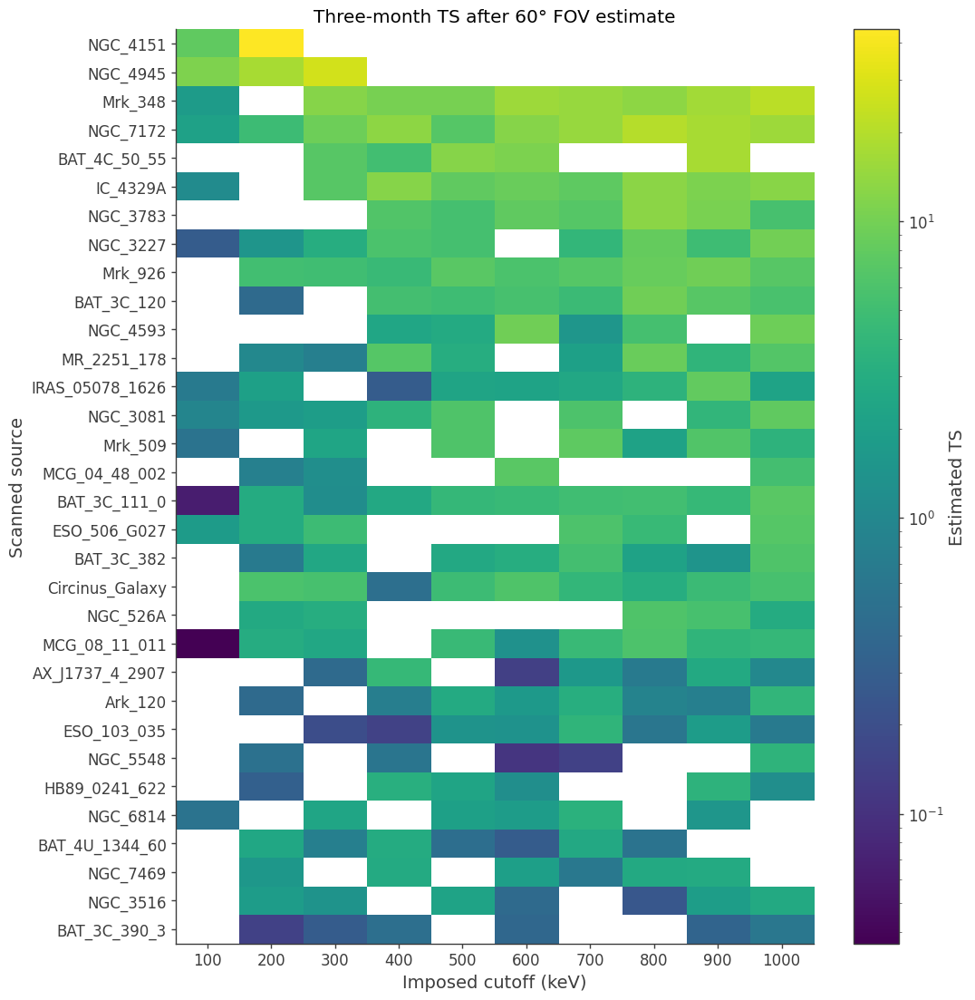

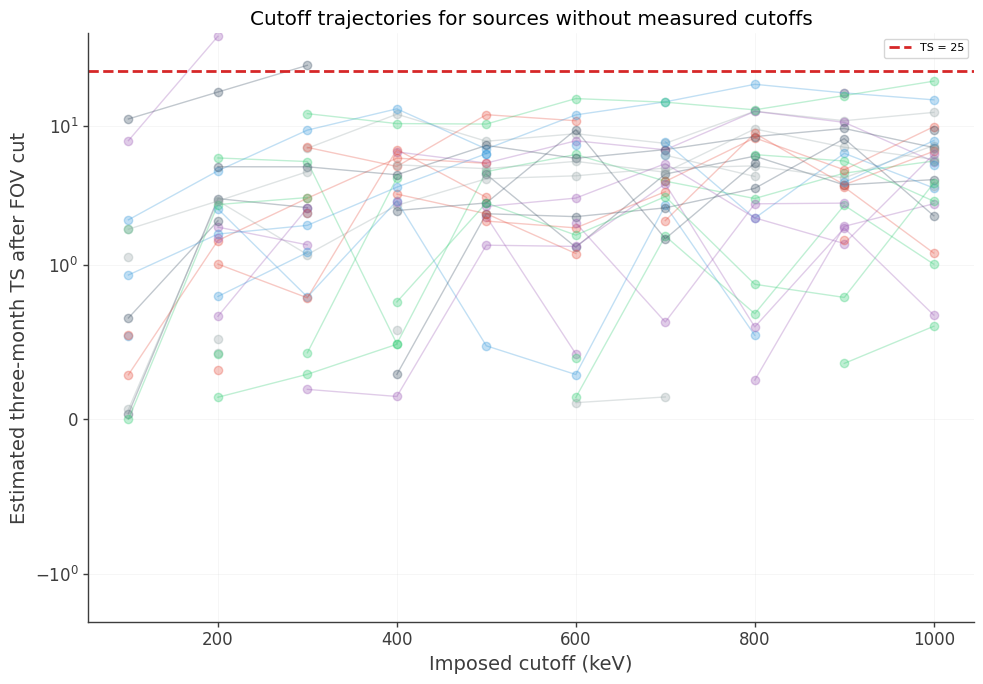

In [ ]:
def significance_matrix(frame, column):
    columns = np.sort(frame["cutoff_keV"].unique())
    matrix = frame.pivot(index="source", columns="cutoff_keV", values=column)
    order = frame.groupby("source")[column].max().sort_values(ascending=False).index
    return matrix.reindex(index=order, columns=columns)


scan_summary = summary.loc[summary["scenario_type"] == "bat_cutoff_scan"]
fixed_summary = summary.loc[summary["scenario_type"] == "balokovic_fixed"]
print("Fixed Balokovic scenarios")
display_tables(fixed_summary.sort_values("catalog_rank"))
print("Evaluated scan scenarios")
display_tables(scan_summary.sort_values(["catalog_rank", "cutoff_keV"]))

if len(scan_summary):
    ts_scan = significance_matrix(scan_summary, "median_ts_3mo_fov_est")
    fig, ax = plt.subplots(figsize=(11, max(7, 0.35 * len(ts_scan))))
    values = ts_scan.to_numpy()
    positive = values[np.isfinite(values) & (values > 0)]
    norm = None
    if len(positive):
        lower, upper = max(positive.min(), 1e-2), positive.max()
        norm = LogNorm(vmin=lower, vmax=max(upper, lower * 1.000001))
    image = ax.imshow(values, aspect="auto", interpolation="nearest",
                      cmap="viridis", norm=norm)
    ax.set_xticks(np.arange(len(ts_scan.columns)),
                  [f"{value:g}" for value in ts_scan.columns])
    ax.set_yticks(np.arange(len(ts_scan.index)), ts_scan.index)
    ax.set(xlabel="Imposed cutoff (keV)", ylabel="Scanned source",
           title="Three-month TS after 60° FOV estimate")
    fig.colorbar(image, ax=ax, label="Estimated TS")
    fig.tight_layout()
    plt.show()

    fig, ax = plt.subplots(figsize=(10, 7))
    for source, group in scan_summary.groupby("source", sort=False):
        group = group.sort_values("cutoff_keV")
        ax.plot(group["cutoff_keV"], group["median_ts_3mo_fov_est"],
                marker="o", alpha=0.3, linewidth=1)
    ax.axhline(TARGET_MEDIAN_TS, color="tab:red", linestyle="--",
               label=f"TS = {TARGET_MEDIAN_TS:g}")
    ax.set(xlabel="Imposed cutoff (keV)",
           ylabel="Estimated three-month TS after FOV cut",
           title="Cutoff trajectories for sources without measured cutoffs")
    ax.set_yscale("symlog", linthresh=1)
    ax.grid(alpha=0.2)
    ax.legend()
    fig.tight_layout()
    plt.show()


## FOV-cut scenario details

The tables below show the source/cutoff-specific gains used by the sequential
search. These are count-based significance estimates, not FOV-selected
likelihood refits.

In [ ]:
def estimate_cut_significance(uncut_summary, estimates,
                              exposure_scale_2yr=8.0, target_threshold=25.0):
    combined = uncut_summary.merge(
        estimates[["source", "cutoff_keV", "max_offaxis_deg", "gain", "status"]],
        on=["source", "cutoff_keV"], how="left", validate="one_to_one",
        suffixes=("", "_estimate"),
    )
    status_column = "status_estimate" if "status_estimate" in combined else "status"
    gain_column = "gain_estimate" if "gain_estimate" in combined else "gain"
    valid = ((combined["n_trials"] > 0)
             & (combined["n_valid"] == combined["n_trials"])
             & (combined["n_failed"] == 0)
             & (combined[status_column] == "ok")
             & np.isfinite(combined["median_ts_3mo"])
             & (combined["median_ts_3mo"] >= 0)
             & np.isfinite(combined[gain_column]) & (combined[gain_column] > 0))
    result = combined[[
        "catalog_rank", "source", "scenario_type", "cutoff_keV",
        "max_offaxis_deg", "n_trials", "n_valid", "n_failed",
    ]].copy()
    result["gain"] = combined[gain_column]
    result["ts_3mo_fov_est"] = (
        combined["median_ts_3mo"] * result["gain"] ** 2
    ).where(valid)
    result["ts_24mo_fov_est"] = exposure_scale_2yr * result["ts_3mo_fov_est"]
    result["sigma_3mo_fov_est"] = np.sqrt(result["ts_3mo_fov_est"])
    result["sigma_24mo_fov_est"] = np.sqrt(result["ts_24mo_fov_est"])
    for period in ("3mo", "24mo"):
        result[f"reaches_target_{period}_fov_est"] = pd.Series(
            np.where(valid, result[f"ts_{period}_fov_est"] >= target_threshold, None),
            dtype="boolean",
        )
    result["interpretation"] = np.where(
        valid, "count-based estimate; no cut refit",
        "inconclusive: inspect trials/FOV status",
    )
    return result


fov_significance = estimate_cut_significance(
    summary, fov_estimates, EXPOSURE_SCALE_2YR, TARGET_MEDIAN_TS,
)
np.testing.assert_allclose(
    fov_significance["ts_3mo_fov_est"], summary["median_ts_3mo_fov_est"],
    rtol=1e-12, atol=0, equal_nan=True,
)
print("FOV estimates for evaluated scenarios")
display_tables(fov_estimates.sort_values(["source", "cutoff_keV"]))
print("Estimated three- and 24-month significance")
display_tables(fov_significance.sort_values(["catalog_rank", "cutoff_keV"]))
print("Common background/orientation coverage")
display_tables(fov_coverage)


FOV estimates for evaluated scenarios


,source,cutoff_keV,max_offaxis_deg,signal_counts_no_cut,signal_counts_cut,background_counts_no_cut,background_counts_cut,livetime_fraction,signal_fraction,background_fraction,gain,flux_threshold_ratio,flux_threshold_reduction_percent,status
123,AX_J1737_4_2907,100.0,60.0,1419.987423,1171.269123,1.685934e+08,2.935090e+07,0.172033,0.824845,0.174093,1.976887,0.505846,49.415407,ok
124,AX_J1737_4_2907,200.0,60.0,3033.200065,2469.795075,1.685934e+08,2.935090e+07,0.172033,0.814254,0.174093,1.951504,0.512425,48.757466,ok
125,AX_J1737_4_2907,300.0,60.0,4104.025177,3310.546866,1.685934e+08,2.935090e+07,0.172033,0.806659,0.174093,1.933300,0.517250,48.274972,ok
126,AX_J1737_4_2907,400.0,60.0,4858.269688,3891.145254,1.685934e+08,2.935090e+07,0.172033,0.800932,0.174093,1.919576,0.520948,47.905169,ok
127,AX_J1737_4_2907,500.0,60.0,5420.359740,4316.992844,1.685934e+08,2.935090e+07,0.172033,0.796440,0.174093,1.908810,0.523887,47.611346,ok
128,AX_J1737_4_2907,600.0,60.0,5857.204519,4643.634558,1.685934e+08,2.935090e+07,0.172033,0.792807,0.174093,1.900103,0.526287,47.371279,ok
129,AX_J1737_4_2907,700.0,60.0,6207.595240,4902.750456,1.685934e+08,2.935090e+07,0.172033,0.789799,0.174093,1.892892,0.528292,47.170797,ok
130,AX_J1737_4_2907,800.0,60.0,6495.592231,5113.717743,1.685934e+08,2.935090e+07,0.172033,0.787260,0.174093,1.886807,0.529996,47.000416,ok
131,AX_J1737_4_2907,900.0,60.0,6736.953222,5289.073429,1.685934e+08,2.935090e+07,0.172033,0.785084,0.174093,1.881593,0.531465,46.853534,ok
132,AX_J1737_4_2907,1000.0,60.0,6942.459332,5437.303198,1.685934e+08,2.935090e+07,0.172033,0.783196,0.174093,1.877067,0.532746,46.725393,ok


Estimated three- and 24-month significance


,catalog_rank,source,scenario_type,cutoff_keV,max_offaxis_deg,n_trials,n_valid,n_failed,gain,ts_3mo_fov_est,ts_24mo_fov_est,sigma_3mo_fov_est,sigma_24mo_fov_est,reaches_target_3mo_fov_est,reaches_target_24mo_fov_est,interpretation
0,1,Cen_A,balokovic_fixed,550.0,60.0,20,20,0,1.930263,429.212124,3433.696994,20.717435,58.597756,True,True,count-based estimate; no cut refit
1,2,NGC_4151,bat_cutoff_scan,100.0,60.0,20,20,0,1.990875,7.873924,62.991395,2.806051,7.936712,False,True,count-based estimate; no cut refit
2,2,NGC_4151,bat_cutoff_scan,200.0,60.0,20,20,0,1.953416,44.460221,355.681766,6.667850,18.859527,True,True,count-based estimate; no cut refit
3,3,NGC_2110,balokovic_fixed,300.0,60.0,20,20,0,1.459842,79.463815,635.710517,8.914248,25.213300,True,True,count-based estimate; no cut refit
4,4,Circinus_Galaxy,bat_cutoff_scan,100.0,60.0,20,19,1,1.883951,NaN,NaN,NaN,NaN,<NA>,<NA>,inconclusive: inspect trials/FOV status
5,4,Circinus_Galaxy,bat_cutoff_scan,200.0,60.0,20,20,0,1.814645,5.907968,47.263742,2.430631,6.874863,False,True,count-based estimate; no cut refit
6,4,Circinus_Galaxy,bat_cutoff_scan,300.0,60.0,20,20,0,1.766254,5.567842,44.542737,2.359628,6.674035,False,True,count-based estimate; no cut refit
7,4,Circinus_Galaxy,bat_cutoff_scan,400.0,60.0,20,20,0,1.730587,0.489836,3.918689,0.699883,1.979568,False,False,count-based estimate; no cut refit
8,4,Circinus_Galaxy,bat_cutoff_scan,500.0,60.0,20,20,0,1.703101,4.712179,37.697431,2.170755,6.139823,False,True,count-based estimate; no cut refit
9,4,Circinus_Galaxy,bat_cutoff_scan,600.0,60.0,20,20,0,1.681184,6.258822,50.070576,2.501764,7.076057,False,True,count-based estimate; no cut refit


Common background/orientation coverage


,common_start_unix,common_end_unix,common_livetime_s,background_time_bin_s,excluded_background_counts,excluded_background_percent
0,1.835489e+09,1.843467e+09,6.578054e+06,3600.385309,33589.0,0.019917


## Sources reaching TS ≥ 25

This final cell is self-contained after the compact checkpoint has been written.
It reports each source once at its first evaluated scenario reaching TS ≥ 25 at
three and approximately 24 months. A fixed Baloković source has only its
published cutoff; a scanned source reports the first successful imposed cutoff.

Results loaded from: /Users/parshadkp/Software/cosipy/agn_sensitivity_checkpoints/bat157_mixed_cutoff_scan_compact_results.csv
Three-month detections after the 60° FOV estimate (TS >= 25): 4


,source,catalog_rank,reference_model_type,scenario_type,cutoff_keV,n_trials,n_valid,n_failed,median_ts_3mo,gain,median_ts_3mo_fov_est,duration_months,ts_fov_est,sigma_fov_est
0,NGC_4151,2,Powerlaw,bat_cutoff_scan,200.0,20,20,0,11.651505,1.953416,44.460221,3.0,44.460221,6.667850
1,NGC_4945,5,Powerlaw,bat_cutoff_scan,300.0,20,20,0,6.684214,2.027132,27.467203,3.0,27.467203,5.240916
2,NGC_2110,3,Cutoff_powerlaw,balokovic_fixed,300.0,20,20,0,37.287045,1.459842,79.463815,3.0,79.463815,8.914248
3,Cen_A,1,Cutoff_powerlaw,balokovic_fixed,550.0,20,20,0,115.196383,1.930263,429.212124,3.0,429.212124,20.717435


Approximate 24-month detections after the 60° FOV estimate (TS >= 25): 33


,source,catalog_rank,reference_model_type,scenario_type,cutoff_keV,n_trials,n_valid,n_failed,median_ts_3mo,gain,median_ts_3mo_fov_est,duration_months,ts_fov_est,sigma_fov_est
0,NGC_4151,2,Powerlaw,bat_cutoff_scan,100.0,20,20,0,1.986568,1.990875,7.873924,24.0,62.991395,7.936712
1,NGC_4945,5,Powerlaw,bat_cutoff_scan,100.0,20,20,0,2.446592,2.147301,11.280997,24.0,90.247974,9.499893
2,MCG_05_23_016,10,Cutoff_powerlaw,balokovic_fixed,150.0,20,20,0,1.954427,1.599527,5.000375,24.0,40.002997,6.324792
3,Circinus_Galaxy,4,Powerlaw,bat_cutoff_scan,200.0,20,20,0,1.794134,1.814645,5.907968,24.0,47.263742,6.874863
4,NGC_7172,12,Powerlaw,bat_cutoff_scan,200.0,20,20,0,1.950831,1.564432,4.774554,24.0,38.196434,6.180326
5,Mrk_926,23,Powerlaw,bat_cutoff_scan,200.0,20,20,0,2.322851,1.482596,5.105838,24.0,40.846701,6.391142
6,NGC_4388,7,Cutoff_powerlaw,balokovic_fixed,210.0,20,20,0,4.530155,1.861966,15.705674,24.0,125.645395,11.209166
7,IC_4329A,6,Powerlaw,bat_cutoff_scan,300.0,20,20,0,1.842050,1.940972,6.939690,24.0,55.517520,7.451008
8,BAT_4C_50_55,9,Powerlaw,bat_cutoff_scan,300.0,20,20,0,1.998961,1.876680,7.040197,24.0,56.321574,7.504770
9,Mrk_348,15,Powerlaw,bat_cutoff_scan,300.0,20,20,0,5.537411,1.491486,12.318144,24.0,98.545154,9.926991


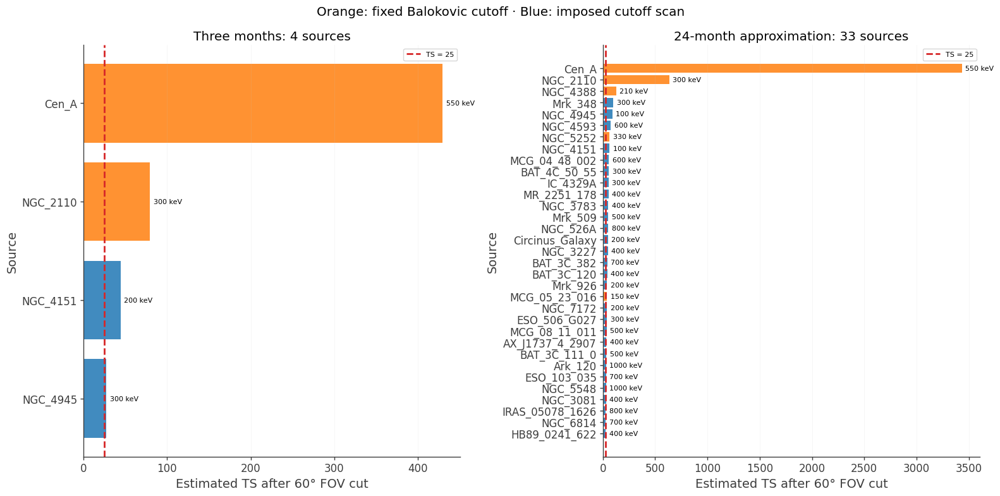

In [6]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

if "COSI_ROOT" not in globals():
    COSI_ROOT = next(
        (path for path in (Path.cwd(), *Path.cwd().parents)
         if (path / "cosipy").is_dir() and (path / "pyproject.toml").is_file()),
        Path.cwd(),
    )
if "CHECKPOINT_PATH" not in globals():
    CHECKPOINT_PATH = (COSI_ROOT / "agn_sensitivity_checkpoints" /
                       "bat157_mixed_cutoff_scan_compact_results.csv")

if "summary" in globals():
    plot_summary = summary.copy()
    plot_target_ts = float(TARGET_MEDIAN_TS)
    plot_fov_deg = float(FOV_MAX_OFFAXIS_DEG)
    plot_trial_months = float(NOMINAL_TRIAL_DURATION_MONTHS)
    results_origin = "current kernel"
else:
    if not CHECKPOINT_PATH.is_file():
        raise FileNotFoundError(
            f"Compact checkpoint not found: {CHECKPOINT_PATH}. Run the sequential "
            "search once to create it."
        )
    plot_summary = pd.read_csv(CHECKPOINT_PATH)
    for column in ("target_median_ts", "fov_max_offaxis_deg",
                   "nominal_trial_duration_months"):
        values = plot_summary[column].dropna().unique()
        if len(values) != 1:
            raise ValueError(f"Checkpoint must contain one unique {column}")
    plot_target_ts = float(plot_summary["target_median_ts"].iloc[0])
    plot_fov_deg = float(plot_summary["fov_max_offaxis_deg"].iloc[0])
    plot_trial_months = float(plot_summary["nominal_trial_duration_months"].iloc[0])
    results_origin = str(CHECKPOINT_PATH)

required = {
    "catalog_rank", "source", "reference_model_type", "scenario_type",
    "cutoff_keV", "n_trials", "n_valid", "n_failed",
    "classification_status", "median_ts_3mo", "gain", "fov_status",
    "median_ts_3mo_fov_est",
}
missing = required - set(plot_summary.columns)
if missing:
    raise ValueError(f"Results are missing columns: {sorted(missing)}")


def first_threshold_crossings(frame, months, scale, threshold):
    valid = ((frame["classification_status"] == "complete")
             & (frame["fov_status"] == "ok")
             & (frame["n_valid"] == frame["n_trials"])
             & (frame["n_failed"] == 0)
             & np.isfinite(frame["median_ts_3mo_fov_est"])
             & (frame["median_ts_3mo_fov_est"] >= 0))
    candidates = frame.loc[valid, [
        "catalog_rank", "source", "reference_model_type", "scenario_type",
        "cutoff_keV", "n_trials", "n_valid", "n_failed",
        "median_ts_3mo", "gain", "median_ts_3mo_fov_est",
    ]].copy()
    candidates["duration_months"] = float(months)
    candidates["ts_fov_est"] = scale * candidates["median_ts_3mo_fov_est"]
    candidates["sigma_fov_est"] = np.sqrt(candidates["ts_fov_est"])
    candidates = candidates.loc[candidates["ts_fov_est"] >= threshold]
    candidates = candidates.sort_values(["catalog_rank", "cutoff_keV"])
    first = candidates.groupby("source", as_index=False, sort=False).first()
    return first.sort_values(["cutoff_keV", "catalog_rank"]).reset_index(drop=True)


scale_3mo = 3.0 / plot_trial_months
scale_24mo = 24.0 / plot_trial_months
if not np.isclose(scale_3mo, 1.0) or not np.isclose(scale_24mo, 8.0):
    raise ValueError("Expected three- and 24-month exposure scales of 1 and 8")
detected_sources_3mo = first_threshold_crossings(
    plot_summary, 3.0, scale_3mo, plot_target_ts,
)
detected_sources_24mo = first_threshold_crossings(
    plot_summary, 24.0, scale_24mo, plot_target_ts,
)

print(f"Results loaded from: {results_origin}")
print(f"Three-month detections after the {plot_fov_deg:g}° FOV estimate "
      f"(TS >= {plot_target_ts:g}): {len(detected_sources_3mo)}")
display(detected_sources_3mo)
print(f"Approximate 24-month detections after the {plot_fov_deg:g}° FOV estimate "
      f"(TS >= {plot_target_ts:g}): {len(detected_sources_24mo)}")
display(detected_sources_24mo)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
for axis, detected, title in (
    (axes[0], detected_sources_3mo, "Three months"),
    (axes[1], detected_sources_24mo, "24-month approximation"),
):
    if detected.empty:
        axis.text(0.5, 0.5, "No sources reached the threshold",
                  ha="center", va="center", transform=axis.transAxes)
        axis.set_axis_off()
        continue
    data = detected.sort_values("ts_fov_est")
    colors = np.where(data["scenario_type"] == "balokovic_fixed",
                      "tab:orange", "tab:blue")
    bars = axis.barh(data["source"], data["ts_fov_est"], color=colors, alpha=0.85)
    axis.axvline(plot_target_ts, color="tab:red", linestyle="--",
                 label=f"TS = {plot_target_ts:g}")
    for bar, cutoff in zip(bars, data["cutoff_keV"]):
        axis.annotate(f"{cutoff:g} keV",
                      xy=(bar.get_width(), bar.get_y() + bar.get_height() / 2),
                      xytext=(4, 0), textcoords="offset points", va="center", fontsize=8)
    axis.set(xlabel=f"Estimated TS after {plot_fov_deg:g}° FOV cut",
             ylabel="Source", title=f"{title}: {len(data)} sources")
    axis.set_xlim(left=0)
    axis.grid(axis="x", alpha=0.2)
    axis.legend()
fig.suptitle("Orange: fixed Balokovic cutoff · Blue: imposed cutoff scan")
fig.tight_layout()
plt.show()


In [7]:
# Rank each evaluated source by its highest valid three-month COSI TS among evaluated cutoffs after the
# 60-degree FOV estimate. The 24-month estimate is 8 times this TS, so its
# ordering is identical. A source with no valid TS remains unranked.
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

rank_root = globals().get("COSI_ROOT")
if rank_root is None:
    rank_root = next(
        (path for path in (Path.cwd(), *Path.cwd().parents)
         if (path / "cosipy").is_dir() and (path / "pyproject.toml").is_file()),
        Path.cwd(),
    )
rank_root = Path(rank_root)
if "plot_summary" in globals():
    rank_results = plot_summary.copy()
elif "summary" in globals():
    rank_results = summary.copy()
else:
    rank_checkpoint = (rank_root / "agn_sensitivity_checkpoints" /
                       "bat157_mixed_cutoff_scan_compact_results.csv")
    rank_results = pd.read_csv(rank_checkpoint)

required_rank_columns = {
    "catalog_rank", "source", "scenario_type", "cutoff_keV", "n_trials",
    "n_valid", "n_failed", "classification_status", "fov_status",
    "median_ts_3mo_fov_est",
}
missing_rank_columns = required_rank_columns - set(rank_results.columns)
if missing_rank_columns:
    raise ValueError(f"Results are missing columns: {sorted(missing_rank_columns)}")

# Extracted from Phillipson, Vogeley, and Boyd (2023), Table 1:
# https://arxiv.org/abs/2211.13774
radio_table_path = (rank_root / "docs/tutorials/spectral_fits/"
                    "Sensitivity_calculator/data/"
                    "phillipson_2023_table1_radio_classes.csv")
radio_table = pd.read_csv(radio_table_path)
if len(radio_table) != 46 or not radio_table["paper_source"].is_unique:
    raise ValueError("Expected the 46 distinct sources in Phillipson et al. Table 1")
if not radio_table["radio_class"].isin(["RQ", "RL"]).all():
    raise ValueError("Radio table contains an unexpected radio class")
matched_radio = radio_table.dropna(subset=["cosipy_source"])
if not matched_radio["cosipy_source"].is_unique:
    raise ValueError("Radio table maps more than one paper source to a COSI source")
radio_class = dict(zip(
    matched_radio["cosipy_source"],
    matched_radio["radio_class"].map({"RQ": "radio quiet", "RL": "radio loud"}),
))
radio_reference = {name: "Phillipson et al. (2023), Table 1"
                   for name in matched_radio["cosipy_source"]}

# 3C 120 and 3C 390.3 are outside that table. This study identifies both as
# broad-line radio galaxies: https://arxiv.org/abs/astro-ph/0210300
for name in ("BAT_3C_120", "BAT_3C_390_3"):
    radio_class[name] = "radio loud"
    radio_reference[name] = "Gliozzi et al. (2003)"

valid_rank_ts = (
    (rank_results["classification_status"] == "complete")
    & (rank_results["fov_status"] == "ok")
    & (rank_results["n_valid"] == rank_results["n_trials"])
    & (rank_results["n_failed"] == 0)
    & np.isfinite(rank_results["median_ts_3mo_fov_est"])
    & (rank_results["median_ts_3mo_fov_est"] >= 0)
)
best_scenario = (
    rank_results.loc[valid_rank_ts]
    .sort_values(["median_ts_3mo_fov_est", "cutoff_keV"],
                 ascending=[False, True])
    .drop_duplicates("source")
    [["source", "cutoff_keV", "median_ts_3mo_fov_est"]]
    .rename(columns={"cutoff_keV": "best_cutoff_keV",
                     "median_ts_3mo_fov_est": "cosi_ts_3mo_fov_est"})
)
cosi_ranked_sources = (
    rank_results[["catalog_rank", "source", "scenario_type"]]
    .drop_duplicates("source")
    .merge(best_scenario, on="source", how="left", validate="one_to_one")
    .sort_values(["cosi_ts_3mo_fov_est", "catalog_rank"],
                 ascending=[False, True], na_position="last")
    .reset_index(drop=True)
)
cosi_ranked_sources["cosi_rank"] = pd.Series(pd.NA, index=cosi_ranked_sources.index,
                                              dtype="Int64")
has_ts = cosi_ranked_sources["cosi_ts_3mo_fov_est"].notna()
cosi_ranked_sources.loc[has_ts, "cosi_rank"] = np.arange(1, has_ts.sum() + 1)
cosi_ranked_sources["cosi_ts_24mo_fov_est"] = (
    8.0 * cosi_ranked_sources["cosi_ts_3mo_fov_est"]
)
cosi_ranked_sources["radio_class"] = (
    cosi_ranked_sources["source"].map(radio_class).fillna("unclassified")
)
# Nullable Boolean: True = published RQ, False = published RL, NA = no match.
cosi_ranked_sources["is_radio_quiet"] = (
    cosi_ranked_sources["radio_class"]
    .map({"radio quiet": True, "radio loud": False})
    .astype("boolean")
)
cosi_ranked_sources["radio_reference"] = (
    cosi_ranked_sources["source"].map(radio_reference)
    .fillna("no matched classification")
)
cosi_ranked_sources = cosi_ranked_sources[[
    "cosi_rank", "catalog_rank", "source", "is_radio_quiet", "radio_class",
    "radio_reference", "scenario_type", "best_cutoff_keV",
    "cosi_ts_3mo_fov_est", "cosi_ts_24mo_fov_est",
]]

print("COSI rank: descending best valid evaluated three-month TS after the 60° FOV estimate.")
print("The 24-month TS is an exposure scaling and gives the same rank.")
print(f"Radio table loaded from: {radio_table_path}")
print("is_radio_quiet: True = RQ, False = RL, <NA> = unclassified.")
print("Radio loudness can depend on the published classification criterion.")
display(cosi_ranked_sources)
print("Radio class counts (including sources without a valid TS):")
display(cosi_ranked_sources["radio_class"].value_counts().rename_axis("radio_class")
        .to_frame("n_sources"))
# TS = sigma^2 for this detection estimate, so 5 sigma corresponds to TS >= 25.
# Select the first qualifying cutoff among valid evaluated scenarios. Fixed
# Balokovic sources have only their single published cutoff in this search.
five_sigma_ts = 25.0
qualified_24mo = rank_results.loc[valid_rank_ts, [
    "source", "cutoff_keV", "median_ts_3mo_fov_est",
]].copy()
qualified_24mo["ts_24mo_at_lowest_cutoff"] = (
    8.0 * qualified_24mo["median_ts_3mo_fov_est"]
)
qualified_24mo = qualified_24mo.loc[
    qualified_24mo["ts_24mo_at_lowest_cutoff"] >= five_sigma_ts
]
first_24mo_crossing = (
    qualified_24mo.sort_values(["source", "cutoff_keV"])
    .drop_duplicates("source")
    [["source", "cutoff_keV", "ts_24mo_at_lowest_cutoff"]]
    .rename(columns={"cutoff_keV": "lowest_tested_cutoff_24mo_keV"})
)
lowest_cutoff_24mo = (
    cosi_ranked_sources[[
        "cosi_rank", "catalog_rank", "source", "is_radio_quiet",
        "radio_class", "scenario_type",
    ]]
    .merge(first_24mo_crossing, on="source", how="inner", validate="one_to_one")
    .sort_values(["lowest_tested_cutoff_24mo_keV", "cosi_rank"])
    .reset_index(drop=True)
)
lowest_cutoff_24mo["sigma_24mo_at_lowest_cutoff"] = np.sqrt(
    lowest_cutoff_24mo["ts_24mo_at_lowest_cutoff"]
)
print(f"Lowest evaluated cutoff reaching approximately 5 sigma in 24 months "
      f"(estimated TS >= {five_sigma_ts:g}): {len(lowest_cutoff_24mo)} sources")
print("Fixed Balokovic sources were evaluated only at their published cutoff.")
display(lowest_cutoff_24mo)


COSI rank: descending best valid evaluated three-month TS after the 60° FOV estimate.
The 24-month TS is an exposure scaling and gives the same rank.
Radio table loaded from: /Users/parshadkp/Software/cosipy/docs/tutorials/spectral_fits/Sensitivity_calculator/data/phillipson_2023_table1_radio_classes.csv
is_radio_quiet: True = RQ, False = RL, <NA> = unclassified.
Radio loudness can depend on the published classification criterion.


,cosi_rank,catalog_rank,source,is_radio_quiet,radio_class,radio_reference,scenario_type,best_cutoff_keV,cosi_ts_3mo_fov_est,cosi_ts_24mo_fov_est
0,1,1,Cen_A,False,radio loud,"Phillipson et al. (2023), Table 1",balokovic_fixed,550.0,429.212124,3433.696994
1,2,3,NGC_2110,True,radio quiet,"Phillipson et al. (2023), Table 1",balokovic_fixed,300.0,79.463815,635.710517
2,3,2,NGC_4151,True,radio quiet,"Phillipson et al. (2023), Table 1",bat_cutoff_scan,200.0,44.460221,355.681766
3,4,5,NGC_4945,True,radio quiet,"Phillipson et al. (2023), Table 1",bat_cutoff_scan,300.0,27.467203,219.737622
4,5,15,Mrk_348,False,radio loud,"Phillipson et al. (2023), Table 1",bat_cutoff_scan,1000.0,21.113211,168.905691
5,6,12,NGC_7172,True,radio quiet,"Phillipson et al. (2023), Table 1",bat_cutoff_scan,800.0,20.047734,160.381871
6,7,9,BAT_4C_50_55,False,radio loud,"Phillipson et al. (2023), Table 1",bat_cutoff_scan,900.0,17.456020,139.648161
7,8,7,NGC_4388,True,radio quiet,"Phillipson et al. (2023), Table 1",balokovic_fixed,210.0,15.705674,125.645395
8,9,6,IC_4329A,True,radio quiet,"Phillipson et al. (2023), Table 1",bat_cutoff_scan,800.0,12.825000,102.600002
9,10,13,NGC_3783,True,radio quiet,"Phillipson et al. (2023), Table 1",bat_cutoff_scan,800.0,12.793786,102.350285


Radio class counts (including sources without a valid TS):


,n_sources
radio_class,
radio quiet,26
unclassified,10
radio loud,9


Lowest evaluated cutoff reaching approximately 5 sigma in 24 months (estimated TS >= 25): 33 sources
Fixed Balokovic sources were evaluated only at their published cutoff.


,cosi_rank,catalog_rank,source,is_radio_quiet,radio_class,scenario_type,lowest_tested_cutoff_24mo_keV,ts_24mo_at_lowest_cutoff,sigma_24mo_at_lowest_cutoff
0,3,2,NGC_4151,True,radio quiet,bat_cutoff_scan,100.0,62.991395,7.936712
1,4,5,NGC_4945,True,radio quiet,bat_cutoff_scan,100.0,90.247974,9.499893
2,27,10,MCG_05_23_016,True,radio quiet,balokovic_fixed,150.0,40.002997,6.324792
3,6,12,NGC_7172,True,radio quiet,bat_cutoff_scan,200.0,38.196434,6.180326
4,12,23,Mrk_926,True,radio quiet,bat_cutoff_scan,200.0,40.846701,6.391142
5,24,4,Circinus_Galaxy,True,radio quiet,bat_cutoff_scan,200.0,47.263742,6.874863
6,8,7,NGC_4388,True,radio quiet,balokovic_fixed,210.0,125.645395,11.209166
7,5,15,Mrk_348,False,radio loud,bat_cutoff_scan,300.0,98.545154,9.926991
8,7,9,BAT_4C_50_55,False,radio loud,bat_cutoff_scan,300.0,56.321574,7.504770
9,9,6,IC_4329A,True,radio quiet,bat_cutoff_scan,300.0,55.517520,7.451008
